In [1]:
%%javascript

IPython.tab_as_tab_everywhere = function(use_tabs) {
    if (use_tabs === undefined) {
        use_tabs = true; 
    }

    // apply setting to all current CodeMirror instances
    IPython.notebook.get_cells().map(
        function(c) {  return c.code_mirror.options.indentWithTabs=use_tabs;  }
    );
    // make sure new CodeMirror instances created in the future also use this setting
    CodeMirror.defaults.indentWithTabs=use_tabs;

    };

IPython.tab_as_tab_everywhere()

<IPython.core.display.Javascript object>

In [2]:
import numpy as np
from scipy.sparse import coo_matrix
import os
import pandas as pd

from tqdm import tqdm

#from glove.kmerge import kmerge
from utils.chrono import Chrono

import pickle
import glob
import seaborn as sns

from matplotlib import rcParams
rcParams.update({'figure.autolayout': True})

from sklearn.ensemble import IsolationForest #1
from sklearn.cluster import DBSCAN #2

from scipy.spatial import Delaunay

import matplotlib.pyplot as plt
from scipy import spatial
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

from collections import defaultdict
import time
import random

def defaultPlotting():
	sns.set_context("paper")
	#sns.set(rc={"font.size":20,"axes.titlesize":20,"axes.labelsize":20})#'figure.figsize':(11.7,8.27),
	
defaultPlotting()

do_pickle=False
do_undirected=True

/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


In [3]:
with open('knn_matrix.pickle', 'rb') as handle:
	knn_m = pickle.load(handle)

print("Making full K-merge matrix")

rows, cols = knn_m.nonzero()
chosen_k=100

num_cores=32
indexes=[]

num_trajs = int(len(rows)/chosen_k)
print("Total num of trajs. are: ", num_trajs)

for i in range(num_cores):
	il = int(num_trajs/num_cores)
	indexes.append([j for j in range(i*il, i*il+il)])

/tmp/ipykernel_2370944/3471792830.py:2: DeprecationWarning: Please use `csr_matrix` from the `scipy.sparse` namespace, the `scipy.sparse.csr` namespace is deprecated.
  knn_m = pickle.load(handle)


Making full K-merge matrix
Total num of trajs. are:  319366


In [4]:
files = glob.glob('cost_kmerge/kmerge_cost_m*')

print(files, [id1[0] for id1 in indexes])

['cost_kmerge/kmerge_cost_m0.txt', 'cost_kmerge/kmerge_cost_m109780.txt', 'cost_kmerge/kmerge_cost_m119760.txt', 'cost_kmerge/kmerge_cost_m129740.txt', 'cost_kmerge/kmerge_cost_m139720.txt', 'cost_kmerge/kmerge_cost_m149700.txt', 'cost_kmerge/kmerge_cost_m159680.txt', 'cost_kmerge/kmerge_cost_m169660.txt', 'cost_kmerge/kmerge_cost_m179640.txt', 'cost_kmerge/kmerge_cost_m189620.txt', 'cost_kmerge/kmerge_cost_m199600.txt', 'cost_kmerge/kmerge_cost_m19960.txt', 'cost_kmerge/kmerge_cost_m209580.txt', 'cost_kmerge/kmerge_cost_m219560.txt', 'cost_kmerge/kmerge_cost_m229540.txt', 'cost_kmerge/kmerge_cost_m239520.txt', 'cost_kmerge/kmerge_cost_m249500.txt', 'cost_kmerge/kmerge_cost_m259480.txt', 'cost_kmerge/kmerge_cost_m269460.txt', 'cost_kmerge/kmerge_cost_m279440.txt', 'cost_kmerge/kmerge_cost_m289420.txt', 'cost_kmerge/kmerge_cost_m299400.txt', 'cost_kmerge/kmerge_cost_m29940.txt', 'cost_kmerge/kmerge_cost_m309380.txt', 'cost_kmerge/kmerge_cost_m39920.txt', 'cost_kmerge/kmerge_cost_m49900.

In [5]:
kmerge_cost=defaultdict(tuple)
for j in tqdm(range(len(files))):
	with open(files[j]) as f:
		this_index = int(files[j].split("/")[1].split(".")[0].split("_")[2][1:])
		start = [id1[0] for id1 in indexes]
		for i, st in enumerate(start):
# 			print(i, st, this_index)
			if st==this_index:
				this_index=i
		print(this_index)
		for line in f:
			line=line[1:-1]
			arrays = line.split('array([')
			arrays = arrays[1:]
			l=len(arrays)
			i=0
			for arr in arrays:
				if i==l-1:
					val=arr[:-3].split(",")
				else:
					val=arr[:-4].split(",")
				val[1]=val[1][1:]
				for k in range(len(val)):
					if 'e' in val[k]:
						v = val[k].split('e')
# 						if len(v[1][1:])==0:
# 							print(v, i, val[k])
						val[k]=int(float(v[0])*(10**(int(v[1][1:]))))
					else:
						val[k]=int(float(val[k]))
				kmerge_cost[(rows[indexes[this_index][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[this_index][int(i/chosen_k)]*chosen_k + i%chosen_k])] = (float(val[0]), float(val[1]))
				i=i+1
				#print((rows[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k]))

  0%|                                                                               | 0/32 [00:00<?, ?it/s]

0


  3%|██▏                                                                    | 1/32 [00:04<02:04,  4.01s/it]

11


  6%|████▍                                                                  | 2/32 [00:08<02:01,  4.06s/it]

12


... (55 outputs left out)

10


 97%|███████████████████████████████████████████████████████████████████▊  | 31/32 [02:09<00:04,  4.15s/it]

1


100%|██████████████████████████████████████████████████████████████████████| 32/32 [02:14<00:00,  4.19s/it]


In [6]:
with open('knn_matrix_shenzen100.pickle', 'rb') as handle:
	knn_m = pickle.load(handle)

print("Making full K-merge matrix")

rows, cols = knn_m.nonzero()
chosen_k=100

num_cores=32
indexes=[]

num_trajs = int(len(rows)/chosen_k)
print("Total num of trajs. are: ", num_trajs)

for i in range(num_cores):
	il = int(num_trajs/num_cores)
	indexes.append([j for j in range(i*il, i*il+il)])

files = glob.glob('cost_kmerge_shenzen/kmerge_cost_shenzen_m*')

print(files, [id1[0] for id1 in indexes])

Making full K-merge matrix
Total num of trajs. are:  100000
['cost_kmerge_shenzen/kmerge_cost_shenzen_m0.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m12500.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m15625.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m18750.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m21875.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m25000.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m28125.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m31250.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m3125.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m34375.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m37500.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m40625.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m43750.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m46875.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m50000.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m53125.txt', 'cost_kmerge_shenzen/kmerge_cost_shenzen_m56250.txt', 'cost_kmerge_shenzen/kmerg

In [7]:
kmerge_cost_shenzen=defaultdict(tuple)
for j in tqdm(range(len(files))):
	with open(files[j]) as f:
		this_index = int(files[j].split("/")[1].split(".")[0].split("_")[3][1:])
		start = [id1[0] for id1 in indexes]
		for i, st in enumerate(start):
# 			print(i, st, this_index)
			if st==this_index:
				this_index=i
		print(this_index)
		for line in f:
			line=line[1:-1]
			arrays = line.split('array([')
			arrays = arrays[1:]
			l=len(arrays)
			i=0
			for arr in arrays:
				if i==l-1:
					val=arr[:-3].split(",")
				else:
					val=arr[:-4].split(",")
				val[1]=val[1][1:]
				for k in range(len(val)):
					if 'e' in val[k]:
						v = val[k].split('e')
# 						if len(v[1][1:])==0:
# 							print(v, i, val[k])
						val[k]=int(float(v[0])*(10**(int(v[1][1:]))))
					else:
						val[k]=int(float(val[k]))
				kmerge_cost_shenzen[(rows[indexes[this_index][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[this_index][int(i/chosen_k)]*chosen_k + i%chosen_k])] = (float(val[0]), float(val[1]))
				i=i+1
				#print((rows[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k]))

  0%|                                                                               | 0/32 [00:00<?, ?it/s]

0


  3%|██▏                                                                    | 1/32 [00:01<00:35,  1.13s/it]

4


  6%|████▍                                                                  | 2/32 [00:02<00:34,  1.15s/it]

5


... (55 outputs left out)

3


 97%|███████████████████████████████████████████████████████████████████▊  | 31/32 [00:37<00:01,  1.21s/it]

31


100%|██████████████████████████████████████████████████████████████████████| 32/32 [00:38<00:00,  1.20s/it]


In [8]:
from itertools import chain
import networkx as nx

In [9]:
def enumerate_digraphs():
	global num_trajs, chosen_k, kmerge_cost
	g = nx.DiGraph()
	g.add_nodes_from([i for i in range(num_trajs)])
	
	# create a list of possible edges
	empty_i=set()
	for i in tqdm(range(num_trajs)):
		edges = []
		costs={}
		for j in range(chosen_k):
			l, m = rows[i*chosen_k + j], cols[i*chosen_k + j]
			if len(kmerge_cost[(l, m)])==0:
				empty_i.add(l)
			else:
				costs[(l, m)] = kmerge_cost[(l, m)][0][0]
				costs[(m, l)] = kmerge_cost[(l, m)][0][1]
				edge1 = (l, m)
				edge2 = (m, l)
				edges.append(edge1)
				edges.append(edge2)
		#print(edges)
		nx.set_edge_attributes(g, costs, "kmerge")
		g.add_edges_from(edges)
		#break
	print("There are: ", len(empty_i), " trajectories with zero neighbours!")
	return g

In [10]:
# digraphs = enumerate_digraphs()
# print(digraphs)

In [11]:
# if do_pickle:
# 	digraphs = enumerate_digraphs()
# 	print(digraphs)
# 	with open('digraphs.pickle', 'wb') as handle:
# 		pickle.dump(digraphs, handle, protocol=pickle.HIGHEST_PROTOCOL)
# else:
# 	start = time.time()
# 	with open('digraphs.pickle', 'rb') as handle:
# 		digraphs = pickle.load(handle)
# 	end = time.time()
# 	print(end - start, "seconds")

In [12]:
# e = nx.get_edge_attributes(digraphs, "kmerge")

# for ep in e:
# 	print(ep, digraphs.get_edge_data(ep[0], ep[1]))
# 	print(ep, digraphs.get_edge_data(ep[1], ep[0]))

In [13]:
def enumerate_graphs():
	global num_trajs, chosen_k, kmerge_cost
	g = nx.Graph()
	g.add_nodes_from([i for i in range(num_trajs)])
	
	# create a list of possible edges
	#print(num_trajs)
	empty_i=set()
	for i in tqdm(range(num_trajs)):
		edges = []
		costs={}
		for j in range(chosen_k):
			l, m = rows[i*chosen_k + j], cols[i*chosen_k + j]
			if len(kmerge_cost[(l, m)])==0:
				empty_i.add(l)
			else:
				g.add_edge(l, m, weight=kmerge_cost[(l, m)][0])
# 				#print(kmerge_cost[(l, m)])
# 				costs[(l, m)] = kmerge_cost[(l, m)][0]
# 				edge1 = (l, m)
# 				edges.append(edge1)
# 		print(costs.items())
# 		nx.set_edge_attributes(g, costs)
# 		g.add_edges_from(edges)
		#break
	print("There are: ", len(empty_i), " trajectories with zero neighbours!")
	return g

In [14]:
with open('knn_matrix_shenzen100.pickle', 'rb') as handle:
	knn_m = pickle.load(handle)

print("Making full K-merge matrix")

rows, cols = knn_m.nonzero()
chosen_k=100

num_cores=32

num_trajs = int(len(rows)/chosen_k)
print("Total num of trajs. are: ", num_trajs)

def enumerate_graphs_shenzen():
	global num_trajs, chosen_k, kmerge_cost_shenzen
	g = nx.Graph()
	g.add_nodes_from([i for i in range(num_trajs)])
	
	# create a list of possible edges
	#print(num_trajs)
	empty_i=set()
	for i in tqdm(range(num_trajs)):
		edges = []
		costs={}
		for j in range(chosen_k):
			l, m = rows[i*chosen_k + j], cols[i*chosen_k + j]
			if len(kmerge_cost_shenzen[(l, m)])==0:
				empty_i.add(l)
			else:
				g.add_edge(l, m, weight=kmerge_cost_shenzen[(l, m)][0])
# 				#print(kmerge_cost[(l, m)])
# 				costs[(l, m)] = kmerge_cost[(l, m)][0]
# 				edge1 = (l, m)
# 				edges.append(edge1)
# 		print(costs.items())
# 		nx.set_edge_attributes(g, costs)
# 		g.add_edges_from(edges)
		#break
	print("There are: ", len(empty_i), " trajectories with zero neighbours!")
	return g

Making full K-merge matrix
Total num of trajs. are:  100000


In [15]:
graphs = enumerate_graphs_shenzen()
print(graphs)

100%|█████████████████████████████████████████████████████████████| 100000/100000 [02:11<00:00, 758.96it/s]


There are:  0  trajectories with zero neighbours!
Graph with 100000 nodes and 5393298 edges


In [16]:
# if do_undirected:
# # 	graphs = enumerate_digraphs()
# # 	print(graphs)
# 	with open('graphs.pickle', 'wb') as handle:
# 		pickle.dump(graphs, handle, protocol=pickle.HIGHEST_PROTOCOL)
# else:
# 	start = time.time()
# 	with open('graphs.pickle', 'rb') as handle:
# 		graphs = pickle.load(handle)
# 	end = time.time()
# 	print(end - start, "seconds")

In [17]:
def find_num_disconnected_components():
	global digraphs
	
	cluster_ids=set()
	#nodes = digraphs.nodes()
	
	print("Number of strongly connected components are: ", nx.number_strongly_connected_components(digraphs))
	
	c_comp = nx.kosaraju_strongly_connected_components(digraphs)
	
	l_comp = [len(comp) for comp in c_comp]
	
# 	for comp in c_comp:
# 		print(comp)
	
	fig, ax = plt.subplots()
	
	df = pd.Series(l_comp)
	sns.boxplot(df)
	plt.xlabel("Len. of strongly connected comps.")

	plt.savefig("sconnected_comps.pdf")

#find_num_disconnected_components()

In [18]:
def find_num_disconnected_components_not_dir(graphs_):
	
	cluster_ids=set()
	#nodes = digraphs.nodes()
	
	print("Number of connected components are: ", nx.number_connected_components(graphs_))
	
	c_comp = nx.connected_components(graphs_)
	
	l_comp = [len(comp) for comp in c_comp]
	
# 	for comp in c_comp:
# 		print(comp)
	
	fig, ax = plt.subplots()
	
	df = pd.Series(l_comp)
	sns.boxplot(df)
	plt.xlabel("Len. of strongly connected comps.")

	plt.savefig("connected_comps.pdf")

#find_num_disconnected_components_not_dir()

In [19]:
def get_graph_info(g_):
	print(nx.maximal_independent_set(digraphs))

# get_graph_info()

In [20]:
def save_graph(graph,file_name):
	#initialze Figure
	plt.figure(num=None, figsize=(20, 20), dpi=80)
	plt.axis('off')
	fig = plt.figure(1)
	pos = nx.random_layout(graph)
	nx.draw_networkx_nodes(graph,pos)
	nx.draw_networkx_edges(graph,pos)
	nx.draw_networkx_labels(graph,pos)

	cut = 1.00
	xmax = cut * max(xx for xx, yy in pos.values())
	ymax = cut * max(yy for xx, yy in pos.values())
	plt.xlim(0, xmax)
	plt.ylim(0, ymax)

	plt.savefig(file_name,bbox_inches="tight")

#Assuming that the graph g has nodes and edges entered
#save_graph(digraphs,"knn_graph_visual.pdf")

#it can also be saved in .svg, .png. or .ps formats

In [21]:
# with open('knn_matrix.pickle', 'rb') as handle:
# 	knn_m = pickle.load(handle)

knn_m=[]
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5, 

for K_SIZE in tqdm(ck_vals):
	with open('knn_matrix_dakar' + str(K_SIZE) +  '.pickle', 'rb') as handle:
		knn_m.append(pickle.load(handle))

100%|██████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 13.09it/s]


In [22]:
knn_m_random=[]

for K_SIZE in tqdm(ck_vals):
	with open('knn_matrix_random' + str(K_SIZE) +  '.pickle', 'rb') as handle:
		knn_m_random.append(pickle.load(handle))

100%|██████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 14.49it/s]


In [23]:
# print("Making full K-merge matrix")

# rows, cols = knn_m.nonzero()
# chosen_k=100

# num_cores=32
# # indexes=[]

# # for i in range(num_cores):
# # 	il = int(num_trajs/num_cores)
# # 	indexes.append([j for j in range(i*il, i*il+il)])

In [24]:
from multiprocessing import Process
from multiprocessing import Pool, freeze_support
from itertools import repeat
import cProfile

# def get_kmerge_pairs_cost(indexes):
# 	global chosen_k
# 	file = open("kmerge_cost_m" + str(indexes[0]) + ".txt", "w")

# 	for i in indexes:
# 		tp=[]
# 		this_results=[]
# 		for j in range(chosen_k):
# 			traj1=np.zeros((len(tdata_full[rows[i*chosen_k + j]]), 9))
# 			traj2=np.zeros((len(tdata_full[cols[i*chosen_k + j]]), 9))

# 			idd=0
# 			for k in range(len(traj1)):
# 				traj1[k] = np.append(tdata_full[rows[i*chosen_k + j]][k], idd)

# 			for k in range(len(traj2)):
# 				traj2[k] = np.append(tdata_full[cols[i*chosen_k + j]][k], idd+1)

# 			tp.append( np.array([*traj1, *traj2]) )

# 			#tp.append( np.array([tdata_full[rows[i*chosen_k + j]], tdata_full[cols[i*chosen_k + j]]]) )
# 		for m in range(len(tp)):
# 			this_results.append( get_node_pairs_m(tp[m]) )

# 		file.write(str(this_results))
# 	file.close()

# with Pool() as pool_per_key:
# 	pool_per_key.starmap( get_kmerge_pairs_cost, zip(indexes) )

## Optimal Selection of k

In [25]:
best_selection=defaultdict(list)
anon_k=10

prev_key=-1
# for key in tqdm(kmerge_cost.keys()):
# 	if prev_key==-1:
# 		prev_key=key[0]
# 		vals=[]
# 	elif prev_key!=key[0]:
# 		s_val = sorted(vals, key=lambda x: x[1])[:anon_k]
# 		best_selection[prev_key]=s_val
# 		vals=[]
# 		vals.append( (key[1], kmerge_cost[key][1]) )
# 	else:
# 		vals.append( (key[1], kmerge_cost[key][1]) )
# 	prev_key=key[0]

In [26]:
def enumerate_red_graphs():
	global best_selection, anon_k, num_trajs
	
	keys = list(best_selection.keys())
	print(len(keys))
	
	g = nx.DiGraph()
	g.add_nodes_from([i for i in range(len(keys))])
	
	# create a list of possible edges
	empty_i=set()
	for i in tqdm(range(len(keys))):
		edges = []
		costs={}
		for j in range(anon_k):
			l = best_selection[keys[i]][j][0]
			if len(kmerge_cost[(i, l)])==0:
				empty_i.add(l)
			else:
				costs[(i, l)] = best_selection[keys[i]][j][1]
				edge1 = (i, l)
				edges.append(edge1)
		#print(edges)
		nx.set_edge_attributes(g, costs, "kmerge")
		g.add_edges_from(edges)
		#break
	print("There are: ", len(empty_i), " trajectories with zero neighbours!")
	return g

In [27]:
#redgraphs = enumerate_red_graphs()

In [28]:
#find_num_disconnected_components_not_dir(redgraphs)

In [29]:
# sns.ecdfplot(np.array(list(nx.in_degree_centrality(redgraphs).values()))*num_trajs)
# plt.xlim([0, 25])

In [30]:
# sns.ecdfplot(np.array(list(nx.out_degree_centrality(redgraphs).values()))*num_trajs)
# plt.xlim([0, 25])

## Community Detection

In [31]:
from community import community_louvain

partion_there=True

if not partion_there:
	#first compute the best partition
	partition = community_louvain.best_partition(graphs)#, weight='kmerge'
	print("Partioned...")

	#pickling partitions
	with open('community_partitions.pickle', 'wb') as handle:
		pickle.dump(partition, handle, protocol=pickle.HIGHEST_PROTOCOL)
	print("Pickled...")
else:
	with open('community_partitions.pickle', 'rb') as handle:
		partition = pickle.load(handle)

#drawing
# fig, ax = plt.subplots()
# size = float(len(set(partition.values())))
# pos = nx.spring_layout(graphs)
# count = 0.
# for com in set(partition.values()) :
# 	count = count + 1.
# 	list_nodes = [nodes for nodes in partition.keys() if partition[nodes] == com]
# 	nx.draw_networkx_nodes(graphs, pos, list_nodes, node_size = 20, node_color = str(count / size))

# nx.draw_networkx_edges(graphs,pos, alpha=0.5)
# plt.savefig("community_senegal.pdf")
# #plt.show()

In [32]:
with open('od_values.pickle', 'rb') as handle:
	od_dict = pickle.load(handle)

In [33]:
#print(od_dict.keys())

## Shenzen Communities

In [34]:
partion_there_shenzen=True

if not partion_there_shenzen:
	#first compute the best partition
	partition_shenzen = community_louvain.best_partition(graphs)#, weight='kmerge'
	print("Partioned...")

	#pickling partitions
	with open('community_partitions_shenzen.pickle', 'wb') as handle:
		pickle.dump(partition_shenzen, handle, protocol=pickle.HIGHEST_PROTOCOL)
	print("Pickled...")
else:
	with open('community_partitions_shenzen.pickle', 'rb') as handle:
		partition_shenzen = pickle.load(handle)

In [35]:
def plot_dist(dt, xlab, name, ylab=""):
	fig, axi = plt.subplots(1, 1)
	
	df = pd.DataFrame(dt)
	df.columns=["size"]
	
	#print(df)
	sns.ecdfplot(data=df)
	
	plt.xlabel(xlab)
	if len(ylab):
		plt.ylabel(ylab)
	#plt.legend()
# 	if xlab[-6:]=="random":
# 		plt.xlim([0, 200])
# 	else:
# 		plt.xlim([0, 5])
	axi.get_legend().remove()
	plt.savefig(str(name) + '.pdf')

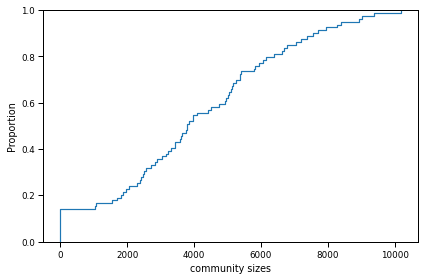

In [36]:
count=defaultdict(int)
for com in set(partition.values()):
	list_nodes = [nodes for nodes in partition.keys() if partition[nodes] == com]
	#print(len(list_nodes))
	count[com]=len(list_nodes)

plot_dist(list(count.values()), "community sizes", "community_sizes")

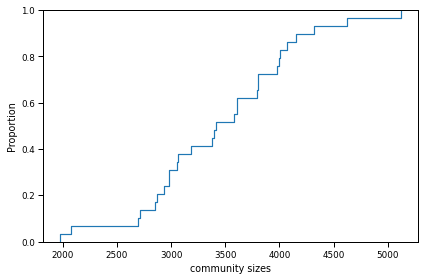

In [37]:
count2=defaultdict(int)
for com in set(partition_shenzen.values()):
	list_nodes = [nodes for nodes in partition_shenzen.keys() if partition_shenzen[nodes] == com]
	#print(len(list_nodes))
	count2[com]=len(list_nodes)

plot_dist(list(count2.values()), "community sizes", "community_sizes_shenzen")

In [38]:
df2=pd.DataFrame(list(partition_shenzen.items()))
del df2[0]
df2.columns=["Community ID"]

print(df2, count2)

       Community ID
0                 0
1                 1
2                 1
3                 2
4                 3
...             ...
99995            16
99996            13
99997             0
99998             7
99999             0

[100000 rows x 1 columns] defaultdict(<class 'int'>, {0: 4624, 1: 4069, 2: 4149, 3: 4001, 4: 3581, 5: 4317, 6: 3974, 7: 3378, 8: 2871, 9: 2980, 10: 3800, 11: 3612, 12: 3607, 13: 2709, 14: 5118, 15: 2936, 16: 2697, 17: 3395, 18: 3179, 19: 1977, 20: 2850, 21: 2976, 22: 3799, 23: 3063, 24: 3052, 25: 3996, 26: 3418, 27: 3793, 28: 2079})


In [39]:
df=pd.DataFrame(list(partition.items()))
del df[0]
df.columns=["Community ID"]

print(df)

        Community ID
0                  0
1                  1
2                  2
3                  0
4                  0
...              ...
319361            54
319362            50
319363            65
319364            22
319365            67

[319366 rows x 1 columns]


In [40]:
with open('com_values.pickle', 'rb') as handle:
	rcm_array = pickle.load(handle)

with open('com_values_shenzen.pickle', 'rb') as handle:
	rcm_array_shenzen = pickle.load(handle)

# with open('od_values_shenzen.pickle', 'rb') as handle:
# 	od_dict2=pickle.load(handle)

In [41]:
#print(rcm_array)

df["x"]=[val[0] for val in rcm_array]
df["y"]=[val[1] for val in rcm_array]
df["origin_x"]=[od_dict[key][0][0] for key in od_dict.keys()]
df["origin_y"]=[od_dict[key][0][1] for key in od_dict.keys()]
df["destination_x"]=[od_dict[key][1][0] for key in od_dict.keys()]
df["destination_y"]=[od_dict[key][1][1] for key in od_dict.keys()]

In [42]:
print(df)

        Community ID              x             y       origin_x  \
0                  0  340843.342236  1.769507e+06  341817.444257   
1                  1  342271.049262  1.703769e+06  368685.171103   
2                  2  719014.202452  1.687751e+06  719798.885726   
3                  0  340132.141809  1.771056e+06  340134.508841   
4                  0  340352.373498  1.770681e+06  340781.442784   
...              ...            ...           ...            ...   
319361            54  292325.367363  1.584980e+06  291736.966385   
319362            50  548624.558771  1.621800e+06  549389.059443   
319363            65  467587.481717  1.539682e+06  467589.791760   
319364            22  402745.980048  1.641555e+06  404848.139353   
319365            67  773426.635616  1.649079e+06  773648.186248   

            origin_y  destination_x  destination_y  
0       1.768134e+06  341817.444257   1.768134e+06  
1       1.727170e+06  368729.011652   1.727877e+06  
2       1.686792e+06  71

In [43]:
df2["x"]=[val[0] for val in rcm_array_shenzen]
df2["y"]=[val[1] for val in rcm_array_shenzen]

print(df2)

       Community ID             x             y
0                 0  1.268758e+07  2.593489e+06
1                 1  1.268321e+07  2.593393e+06
2                 1  1.268546e+07  2.594979e+06
3                 2  1.269061e+07  2.581751e+06
4                 3  1.269620e+07  2.589706e+06
...             ...           ...           ...
99995            16  1.269430e+07  2.584776e+06
99996            13  1.268847e+07  2.585699e+06
99997             0  1.269082e+07  2.592945e+06
99998             7  1.268669e+07  2.590044e+06
99999             0  1.269010e+07  2.590259e+06

[100000 rows x 3 columns]


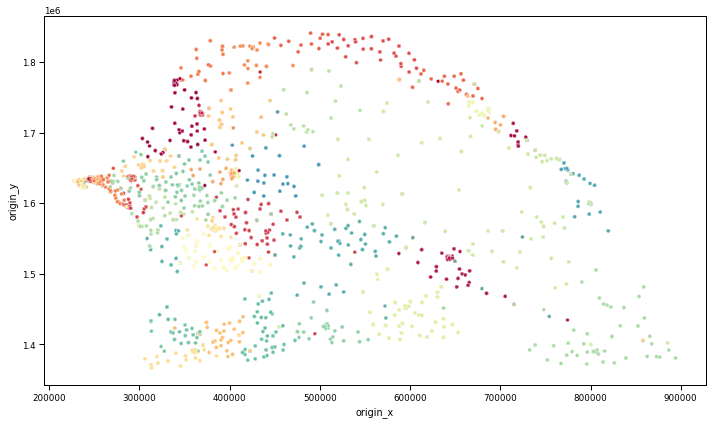

In [44]:
plt.figure(figsize=(10, 6))
axi = plt.gca()
#fig, axi = plt.subplots(1, 1)

g = sns.scatterplot(x="origin_x", y="origin_y", data=df, c=df["Community ID"], cmap= "Spectral", s=12) #, hue="Community ID"
#g.fig.set_figwidth(8.27)
#g.fig.set_figheight(11.7)

#axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

# #hide x-axis
# axi.get_xaxis().set_visible(False)

# #hide y-axis 
# axi.get_yaxis().set_visible(False)
plt.savefig("plot_communities.pdf")

## Analysing spatial costs

In [45]:
st_devs=defaultdict(list)
commune_com=defaultdict(list)

for index, row in df.iterrows():
	st_devs[row["Community ID"]].append( (row["x"], row["y"]) )
	commune_com[row["Community ID"]].append( (row["origin_x"], row["origin_y"]) )

In [46]:
for key in commune_com.keys():
	com_x, com_y = 0, 0
	for traj in commune_com[key]:
		com_x = com_x + traj[0]
		com_y = com_y + traj[1]
	commune_com[key]=(com_x/count[key], com_y/count[key])

In [47]:
df_com = pd.DataFrame.from_dict(commune_com).T
df_com["Size"] = [count[val] for val in list(df_com.index)]
df_com.columns = ["X", "Y", "Size"]
print(df_com, count, commune_com, df_com[df_com["X"]<300000], np.sum(df_com[df_com["X"]<300000]["Size"]))

                  X             Y  Size
0.0   341757.022691  1.768796e+06  7059
1.0   331678.266413  1.693068e+06  5019
2.0   720464.070272  1.691950e+06  1825
3.0   641690.764072  1.518661e+06  3965
4.0   245531.215430  1.634387e+06  7553
...             ...           ...   ...
75.0  394969.191484  1.580629e+06     1
76.0  283442.672399  1.604130e+06     1
77.0  236301.346953  1.625126e+06     1
78.0  836855.156178  1.451923e+06     1
33.0  237418.747990  1.623410e+06     1

[79 rows x 3 columns] defaultdict(<class 'int'>, {0: 7059, 1: 5019, 2: 1825, 3: 3965, 4: 7553, 5: 2374, 6: 6676, 7: 3432, 8: 4956, 9: 6641, 10: 3763, 11: 9034, 12: 7937, 13: 2064, 14: 3784, 15: 10173, 16: 4519, 17: 2888, 18: 5803, 19: 4406, 20: 9374, 21: 5118, 22: 5250, 23: 1537, 24: 7360, 25: 6386, 26: 2842, 27: 3025, 28: 8922, 29: 5942, 30: 8281, 31: 7198, 32: 8405, 33: 1, 34: 6762, 35: 6063, 36: 7718, 37: 2462, 38: 3297, 39: 3589, 40: 5807, 41: 5378, 42: 5043, 43: 3791, 44: 6145, 45: 1883, 46: 4909, 47: 5165, 4

                  X             Y   Size
4.0   245531.215430  1.634387e+06   7553
6.0   236720.962416  1.627168e+06   6676
12.0  242004.980135  1.632366e+06   7937
15.0  235158.430651  1.627232e+06  10173
16.0  258254.532288  1.634339e+06   4519
20.0  254668.411941  1.628547e+06   9374
21.0  244404.350650  1.631805e+06   5118
24.0  249930.132506  1.634546e+06   7360
25.0  236360.752371  1.631019e+06   6386
28.0  247330.025393  1.629391e+06   8922
30.0  237623.106460  1.632766e+06   8281
34.0  242876.651955  1.634180e+06   6762
35.0  238210.723729  1.629452e+06   6063
36.0  235992.594256  1.629382e+06   7718
39.0  234360.351138  1.629611e+06   3589
40.0  235761.009750  1.625395e+06   5807
41.0  239592.997591  1.626722e+06   5378
42.0  232125.909328  1.629570e+06   5043
43.0  239986.231500  1.633723e+06   3791
44.0  236632.034939  1.624168e+06   6145
47.0  234598.155272  1.632135e+06   5165
49.0  240079.189296  1.630749e+06   5403
77.0  236301.346953  1.625126e+06      1
33.0  237418.747

ValueError: Index([ 4.0,  6.0, 12.0, 15.0, 16.0, 20.0, 21.0, 24.0, 25.0, 28.0, 30.0, 34.0,
       35.0, 36.0, 39.0, 40.0, 41.0, 42.0, 43.0, 44.0, 47.0, 49.0, 77.0, 33.0],
      dtype='float64') is not a valid value for color

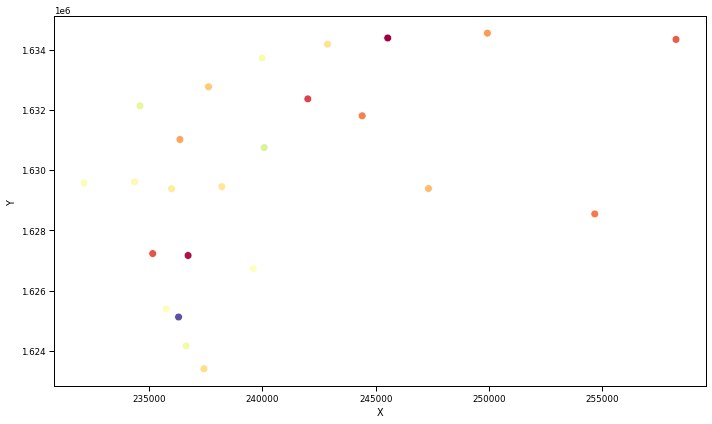

In [48]:
plt.figure(figsize=(10, 6))
axi = plt.gca()
#fig, axi = plt.subplots(1, 1)

df_dakar=df_com[df_com["X"]<260000]
print(df_com[df_com["X"]<260000])

g = sns.scatterplot(x="X", y="Y", data=df_com[df_com["X"]<260000], c=df_com[df_com["X"]<260000].index, cmap= "Spectral", s=60, hue="Size") #, hue="Community ID"
#g.fig.set_figwidth(8.27)
#g.fig.set_figheight(11.7)

#axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

# #hide x-axis
# axi.get_xaxis().set_visible(False)

# #hide y-axis 
# axi.get_yaxis().set_visible(False)
plt.savefig("plot_communities_com3.pdf")

In [49]:
# plt.figure(figsize=(10, 6))
# axi = plt.gca()
# #fig, axi = plt.subplots(1, 1)

# g = sns.scatterplot(x="X", y="Y", data=df_com[df_com.index.isin(com_id_size)], s=100, hue='Size') #data=df_com[df_com.index.isin(com_id_size)]["Size"], c=df_com[df_com.index.isin(com_id_size)]["Size"], cmap= "Spectral", hue="Community ID"
# #g.fig.set_figwidth(8.27)
# #g.fig.set_figheight(11.7)

# #axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

# # #hide x-axis
# # axi.get_xaxis().set_visible(False)

# # #hide y-axis 
# # axi.get_yaxis().set_visible(False)

# axi.set_xlim([200000, 900000])
# axi.set_ylim([1300000, 1900000])
# plt.savefig("plot_communities_com.pdf")

In [50]:
# plt.figure(figsize=(10, 6))
# axi = plt.gca()
# #fig, axi = plt.subplots(1, 1)

# g = sns.scatterplot(x="X", y="Y", data=df_com[df_com.index.isin(com_id_density)], s=100, hue=df_com[df_com.index.isin(com_id_density)].index) #data=df_com[df_com.index.isin(com_id_size)]["Size"], c=df_com[df_com.index.isin(com_id_size)]["Size"], cmap= "Spectral", hue="Community ID"
# #g.fig.set_figwidth(8.27)
# #g.fig.set_figheight(11.7)

# #axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

# # #hide x-axis
# # axi.get_xaxis().set_visible(False)

# # #hide y-axis 
# # axi.get_yaxis().set_visible(False)

# axi.set_xlim([200000, 900000])
# axi.set_ylim([1300000, 1900000])
# plt.savefig("plot_communities_com2.pdf")

# #com_id_density = [39.0, 7.0, 57.0, 65.0] #density variation ids

In [51]:
for key in st_devs.keys():
	st_devs[key]=(np.std([point[0] for point in st_devs[key]])/1000.0, np.std([point[1] for point in st_devs[key]])/1000.0)

print(st_devs)

defaultdict(<class 'list'>, {0.0: (6.34393007015278, 6.68956657262319), 1.0: (19.606940204310163, 18.446180536114543), 2.0: (6.210751758038246, 5.697825357799379), 3.0: (18.66115397043221, 14.185608477220677), 4.0: (1.0305643270347746, 0.9575285774037566), 5.0: (3.2638597005419574, 4.091080057050806), 6.0: (0.562488973697394, 0.7829780912348784), 7.0: (1.0180471414846815, 1.260705721531738), 8.0: (20.111350184278024, 18.38470540740551), 9.0: (6.96495660127331, 5.945374722929679), 10.0: (29.032801429149345, 14.074741705007686), 11.0: (1.5336460732806074, 1.89448820816153), 12.0: (0.6555927050571351, 0.7422600020033144), 13.0: (17.516964312596276, 7.049194097068643), 14.0: (20.90858920565193, 11.32153220682726), 15.0: (0.5630541205826572, 0.8890545383269827), 16.0: (4.8341873518119955, 5.185191981055995), 17.0: (16.43194326853052, 14.854659157784932), 18.0: (8.175840254925678, 7.621630088293289), 19.0: (16.937839542243466, 18.350815222618994), 20.0: (2.3592956074279283, 1.433228458909205

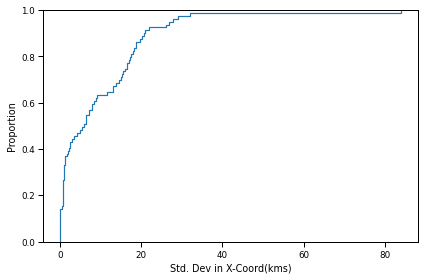

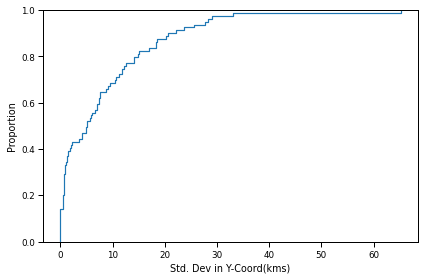

In [52]:
plot_dist([val[0] for val in st_devs.values()], "Std. Dev in X-Coord(kms)", "spatial_varriation_x")

plot_dist([val[1] for val in st_devs.values()], "Std. Dev in Y-Coord(kms)", "spatial_varriation_y")

In [53]:
from scipy.spatial import ConvexHull, convex_hull_plot_2d

coms_com=defaultdict(list)

for index, row in df.iterrows():
	coms_com[row["Community ID"]].append( (row["x"], row["y"]) )

In [55]:
hdensity=defaultdict(tuple)

for key in coms_com.keys():
	if len(coms_com[key])>1:
		hull = ConvexHull(coms_com[key])
		hdensity[key]=(len(coms_com[key]), hull.volume/len(coms_com[key]))
	
# 	else:
# 		hdensity[key]=(1, 1)

hdensity = pd.DataFrame(hdensity).T
hdensity.columns=["size", "density"]

<Axes: xlabel='density', ylabel='Count'>

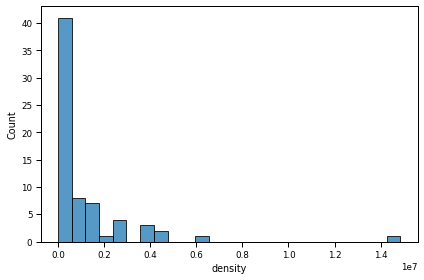

In [56]:
sns.histplot(hdensity["density"])

<Axes: xlabel='size', ylabel='Count'>

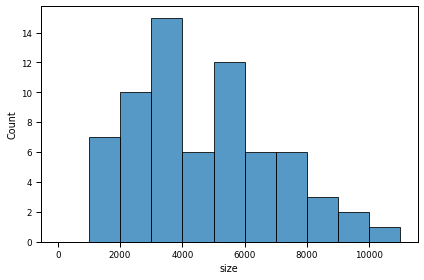

In [57]:
sns.histplot(hdensity["size"], bins=[0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 11000])

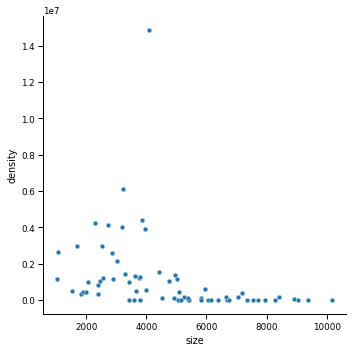

In [58]:
g = sns.relplot(data=hdensity, x='size', y='density')

## Analysing spatial costs Shenzen

In [59]:
st_devs=defaultdict(list)
commune_com=defaultdict(list)

for index, row in df2.iterrows():
	st_devs[row["Community ID"]].append( (row["x"], row["y"]) )
	commune_com[row["Community ID"]].append( (row["x"], row["y"]) )

for key in commune_com.keys():
	com_x, com_y = 0, 0
	for traj in commune_com[key]:
		com_x = com_x + traj[0]
		com_y = com_y + traj[1]
	commune_com[key]=(com_x/count2[key], com_y/count2[key])

df_com2 = pd.DataFrame.from_dict(commune_com).T
df_com2["Size"] = [count2[val] for val in list(df_com2.index)]
df_com2.columns = ["X", "Y", "Size"]

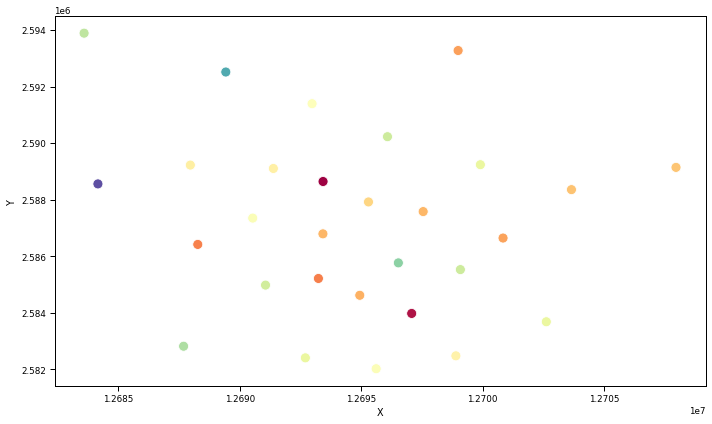

In [60]:
plt.figure(figsize=(10, 6))
axi = plt.gca()
#fig, axi = plt.subplots(1, 1)

g = sns.scatterplot(x="X", y="Y", data=df_com2, c=df_com2["Size"], cmap= "Spectral", s=100) #, hue="Community ID"
#g.fig.set_figwidth(8.27)
#g.fig.set_figheight(11.7)

#axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

# #hide x-axis
# axi.get_xaxis().set_visible(False)

# #hide y-axis 
# axi.get_yaxis().set_visible(False)
plt.savefig("plot_communities_com_shenzen.pdf")

In [61]:
coms_com=defaultdict(list)

for index, row in df2.iterrows():
	coms_com[row["Community ID"]].append( (row["x"], row["y"]) )

hdensity2=defaultdict(tuple)

for key in coms_com.keys():
	if len(coms_com[key])>1:
		hull = ConvexHull(coms_com[key])
		hdensity2[key]=(len(coms_com[key]), hull.volume/len(coms_com[key]))
	
# 	else:
# 		hdensity[key]=(1, 1)

hdensity2 = pd.DataFrame(hdensity2).T
hdensity2.columns=["size", "density"]

<Axes: xlabel='density', ylabel='Count'>

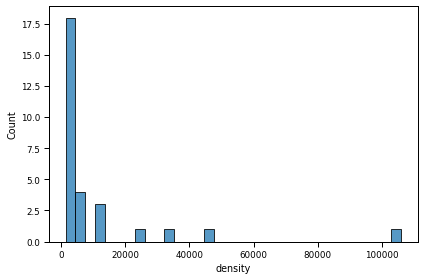

In [62]:
sns.histplot(hdensity2["density"])

<Axes: xlabel='size', ylabel='Count'>

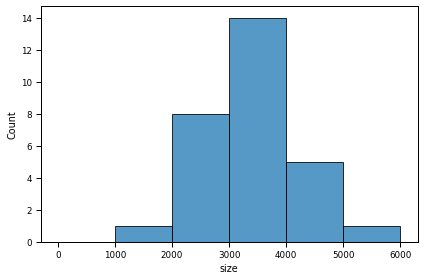

In [63]:
sns.histplot(hdensity2["size"], bins=[0, 1000, 2000, 3000, 4000, 5000, 6000])

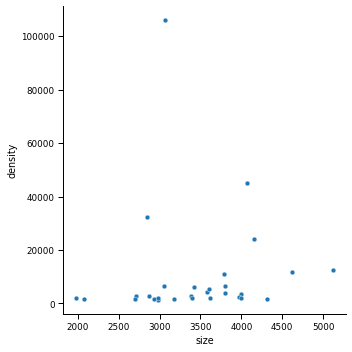

In [64]:
g = sns.relplot(data=hdensity2, x='size', y='density')

In [65]:
size_min, size_max = 3000, 4000

hd = hdensity[hdensity["size"]>size_min]
hd = hd[hd["size"]<size_max]
print(hd)

hd2 = hdensity2[hdensity2["size"]>size_min]
hd2 = hd2[hd2["size"]<size_max]
print(hd2)

        size       density
3.0   3965.0  3.894161e+06
7.0   3432.0  1.772690e+04
10.0  3763.0  1.199060e+06
14.0  3784.0  1.257547e+06
27.0  3025.0  2.135671e+06
38.0  3297.0  1.443916e+06
39.0  3589.0  1.230683e+03
43.0  3791.0  3.976502e+03
48.0  3173.0  4.015592e+06
52.0  3650.0  5.169616e+05
55.0  3205.0  6.120672e+06
57.0  3976.0  5.349870e+05
58.0  3615.0  1.302356e+06
61.0  3415.0  9.738794e+05
65.0  3854.0  4.385194e+06
        size        density
4.0   3581.0    4288.315039
6.0   3974.0    2369.993166
7.0   3378.0    2878.195832
10.0  3800.0    6651.768796
11.0  3612.0    1921.575572
12.0  3607.0    5217.418016
17.0  3395.0    2008.030632
18.0  3179.0    1582.148117
22.0  3799.0    3959.164863
23.0  3063.0  105912.595293
24.0  3052.0    6524.529147
25.0  3996.0    1914.285415
26.0  3418.0    6305.851356
27.0  3793.0   10864.524687


In [66]:
size_min, size_max = 1000, 2000

hd = hdensity[hdensity["size"]>size_min]
hd = hd[hd["size"]<size_max]
print(hd)

hd2 = hdensity2[hdensity2["size"]>size_min]
hd2 = hd2[hd2["size"]<size_max]
print(hd2)

        size       density
2.0   1825.0  3.051077e+05
23.0  1537.0  5.082027e+05
45.0  1883.0  4.176935e+05
51.0  1975.0  4.655901e+05
63.0  1686.0  2.948411e+06
66.0  1063.0  2.660118e+06
67.0  1028.0  1.161077e+06
        size      density
19.0  1977.0  1934.237624


In [67]:
size_min, size_max = 2000, 3000

hd = hdensity[hdensity["size"]>size_min]
hd = hd[hd["size"]<size_max]
print(hd)

hd2 = hdensity2[hdensity2["size"]>size_min]
hd2 = hd2[hd2["size"]<size_max]
print(hd2)

        size       density
5.0   2374.0  3.085463e+05
13.0  2064.0  9.877838e+05
17.0  2888.0  1.155847e+06
26.0  2842.0  2.594845e+06
37.0  2462.0  1.025360e+06
53.0  2718.0  4.137605e+06
60.0  2564.0  1.222915e+06
62.0  2398.0  8.422517e+05
64.0  2508.0  2.960098e+06
68.0  2298.0  4.227452e+06
        size       density
9.0   2980.0   1442.950548
13.0  2709.0   2947.985639
15.0  2936.0   1502.156206
16.0  2697.0   1517.315793
20.0  2850.0  32273.786336
21.0  2976.0   1846.284822
28.0  2079.0   1750.590477
8.0   2871.0   2802.274263


In [68]:
size_min, size_max = 4000, 5000

hd = hdensity[hdensity["size"]>size_min]
hd = hd[hd["size"]<size_max]
print(hd)

hd2 = hdensity2[hdensity2["size"]>size_min]
hd2 = hd2[hd2["size"]<size_max]
print(hd2)

        size       density
8.0   4956.0  1.398203e+06
16.0  4519.0  1.367987e+05
19.0  4406.0  1.556404e+06
46.0  4909.0  1.018417e+05
50.0  4094.0  1.485976e+07
54.0  4739.0  1.052991e+06
       size       density
0.0  4624.0  11607.328222
1.0  4069.0  45040.310412
2.0  4149.0  24215.552691
3.0  4001.0   3370.060464
5.0  4317.0   1481.789672


In [69]:
#density_shenzen = [1400, 2000]
#density_senegal = [1.0, 1.5]*(10**6)

#community size bin = [3000, 4000]

In [70]:
com_id_size = [67, 37, 10, 54] #size variation
com_id_size_shenzen = [19, 9, 18, 5] #size variation shenzen

In [71]:
com_id_density = [39.0, 7.0, 57.0, 65.0] #density variation ids
com_density = [1.230683e+03, 1.772690e+04, 5.349870e+05, 4.385194e+06] #corresponding densities

com_id_density_shenzen = [18.0, 12.0, 27.0, 23.0] #density variation shenzen
com_density_shenzen = [1582.148117, 5217.418016, 10864.524687, 105912.595293] #corresponding densities

In [72]:
com_size = ["1000-2000", "2000-3000", "3000-4000", "4000-5000"]

In [73]:
ls_trajs=defaultdict(list)
ls_trajs_shenzen=defaultdict(list)

for index, row in df.iterrows():
	ls_trajs[row["Community ID"]].append( index )

for index, row in df2.iterrows():
	ls_trajs_shenzen[row["Community ID"]].append( index )

In [74]:
print(len(ls_trajs_shenzen[19]), len(ls_trajs[67]))

1977 1028


In [75]:
for j in range(4):
	with open('com_trajectories_size' + str(com_id_size[j]) + '.pickle', 'wb') as handle:
		pickle.dump(ls_trajs[com_id_size[j]], handle, protocol=pickle.HIGHEST_PROTOCOL)
	
	with open('com_trajectories_shenzen_size' + str(com_id_size_shenzen[j]) + '.pickle', 'wb') as handle:
		pickle.dump(ls_trajs_shenzen[com_id_size_shenzen[j]], handle, protocol=pickle.HIGHEST_PROTOCOL)
	
	with open('com_trajectories_density' + str(com_id_density[j]) + '.pickle', 'wb') as handle:
		pickle.dump(ls_trajs[com_id_density[j]], handle, protocol=pickle.HIGHEST_PROTOCOL)
	
	with open('com_trajectories_shenzen_density' + str(com_id_density_shenzen[j]) + '.pickle', 'wb') as handle:
		pickle.dump(ls_trajs_shenzen[com_id_density_shenzen[j]], handle, protocol=pickle.HIGHEST_PROTOCOL)

## Optimal Merge

In [76]:
trajs_dakar = [key for key in partition.keys() if partition[key]==42][:5000]
print(trajs_dakar)

#pickling investigated trajs. of Dakar
with open('dakar_trajectories.pickle', 'wb') as handle:
	pickle.dump(trajs_dakar, handle, protocol=pickle.HIGHEST_PROTOCOL)

[79, 135, 544, 626, 680, 811, 1107, 1122, 1130, 1143, 1151, 1158, 1159, 1190, 1349, 1378, 1457, 1592, 1598, 1631, 1660, 1672, 1691, 1718, 1771, 1833, 1942, 2171, 2196, 2272, 2316, 2378, 2568, 2594, 2610, 2649, 2655, 2696, 2783, 2863, 2878, 2947, 2990, 3080, 3117, 3127, 3131, 3169, 3177, 3184, 3321, 3397, 3606, 3613, 3788, 3805, 3842, 4365, 4408, 4620, 4662, 4718, 4740, 4756, 4766, 4844, 4901, 4988, 5030, 5160, 5193, 5606, 5851, 5868, 5973, 6369, 6451, 6501, 6521, 6530, 6618, 6620, 6665, 6722, 6736, 6941, 7061, 7103, 7120, 7121, 7309, 7352, 7587, 7670, 7717, 7759, 7830, 7846, 8027, 8062, 8068, 8069, 8191, 8219, 8310, 8464, 8469, 8512, 8529, 8616, 8823, 8830, 8852, 8915, 8940, 9037, 9067, 9117, 9123, 9152, 9682, 9709, 9802, 9813, 10013, 10119, 10137, 10156, 10260, 10405, 10556, 10572, 10639, 10716, 10859, 10879, 10915, 10927, 10931, 10997, 11021, 11073, 11084, 11093, 11122, 11137, 11212, 11216, 11291, 11299, 11301, 11334, 11351, 11402, 11404, 11560, 11693, 11741, 11855, 12135, 12143, 122

# Full NxN k-merge trajectories (5000) + hungarian on the complete matrix

In [77]:
print("Retreiving full K-merge matrix for 5000 trajs. of Dakar")

Retreiving full K-merge matrix for 5000 trajs. of Dakar


In [78]:
indexes=[]
num_trajs_dakar=5000

for i in range(num_cores):
	il = int(len(trajs_dakar)/num_cores)
	indexes.append([j for j in range(i*il, i*il+il)])

In [79]:
# files = glob.glob('cost_kmerge_5000/kmerge_cost*')

# print(files, [id1[0] for id1 in indexes])

In [80]:
with open('kmerge_costs_dakar_trajs.pickle', 'rb') as handle:
	kmerge_cost_dakar = pickle.load(handle)

In [81]:
# kmerge_cost_dakar=defaultdict(tuple)
# for j in tqdm(range(len(files))):
# 	with open(files[j]) as f:
# 		this_index = int(files[j].split("/")[1].split(".")[0].split("_")[3])
# 		start = [id1[0] for id1 in indexes]
# 		for i, st in enumerate(start):
# # 			print(i, st, this_index)
# 			if st==this_index:
# 				this_index=i
# 		print(this_index)
# 		for line in f:
# 			line=line[1:-1]
# 			arrays = line.split('array([')
# 			arrays = arrays[1:]
# 			l=len(arrays)
# 			print(l)
# 			i=0
# 			for arr in arrays:
# 				if i==l-1:
# 					val=arr[:-3].split(",")
# 				else:
# 					val=arr[:-4].split(",")
# 				val[1]=val[1][1:]
# 				for k in range(len(val)):
# 					if 'e' in val[k]:
# 						v = val[k].split('e')
# # 						if len(v[1][1:])==0:
# # 							print(v, i, val[k])
# 						val[k]=int(float(v[0])*(10**(int(v[1][1:]))))
# 					else:
# 						val[k]=int(float(val[k]))
# # 				print((indexes[this_index][int(i/len(trajs_dakar))], i%len(trajs_dakar)))
# 				kmerge_cost_dakar[(indexes[this_index][int(i/len(trajs_dakar))], i%len(trajs_dakar))] = (float(val[0]), float(val[1]))
# 				i=i+1
# 				#print((rows[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k]))

In [82]:
# a= set()
# for key in kmerge_cost_dakar.keys():
# 	a.add(key[0])

# print(a, len(a))

In [83]:
print("Retreiving full K-merge matrix for 5000 random trajs. of Senegal")

with open('senegal_trajs_random_5000.pickle', 'rb') as handle:
	trajs_senegal_random = pickle.load(handle)

Retreiving full K-merge matrix for 5000 random trajs. of Senegal


In [84]:
indexes_random=[]
num_trajs_random=5000

for i in range(num_cores):
	il = int(len(trajs_senegal_random)/num_cores)
	indexes_random.append([j for j in range(i*il, i*il+il)])

In [85]:
with open('kmerge_costs_random_trajs.pickle', 'rb') as handle:
	kmerge_cost_senegal_random = pickle.load(handle)

In [86]:
# files = glob.glob('cost_kmerge_random_5000/kmerge_cost*')

# kmerge_cost_senegal_random=defaultdict(tuple)
# for j in tqdm(range(len(files))):
# 	with open(files[j]) as f:
# 		this_index = int(files[j].split("/")[1].split(".")[0].split("_")[4])
# 		start = [id1[0] for id1 in indexes]
# 		for i, st in enumerate(start):
# # 			print(i, st, this_index)
# 			if st==this_index:
# 				this_index=i
# 		print(this_index)
# 		for line in f:
# 			line=line[1:-1]
# 			arrays = line.split('array([')
# 			arrays = arrays[1:]
# 			l=len(arrays)
# 			i=0
# 			for arr in arrays:
# 				if i==l-1:
# 					val=arr[:-3].split(",")
# 				else:
# 					val=arr[:-4].split(",")
# 				val[1]=val[1][1:]
# 				for k in range(len(val)):
# 					if 'e' in val[k]:
# 						v = val[k].split('e')
# # 						if len(v[1][1:])==0:
# # 							print(v, i, val[k])
# 						val[k]=int(float(v[0])*(10**(int(v[1][1:]))))
# 					else:
# 						val[k]=int(float(val[k]))
# # 				print(trajs_dakar[indexes[int(i/len(trajs_dakar))]], trajs_dakar[i%len(trajs_dakar)])
# 				kmerge_cost_senegal_random[(indexes_random[this_index][int(i/len(trajs_senegal_random))], i%len(trajs_senegal_random))] = (float(val[0]), float(val[1]))
# 				i=i+1
# 				#print((rows[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k], cols[indexes[j][int(i/chosen_k)]*chosen_k + i%chosen_k]))

In [87]:
index_count=defaultdict(int)

for key in kmerge_cost_dakar.keys():
	index_count[key[0]]=index_count[key[0]]+1

a=set(list(index_count.keys()))
b=set([i for i in range(5000)])
print(b-a)
# print([key for key in index_count.keys() if index_count[key]!=len(trajs_dakar)])

set()


In [88]:
# print(zip(indexes))

In [89]:
index_count=defaultdict(int)

for key in kmerge_cost_senegal_random.keys():
	index_count[key[0]]=index_count[key[0]]+1

a=set(list(index_count.keys()))
b=set([i for i in range(5000)])
print(b-a)
# print([key for key in index_count.keys() if index_count[key]!=len(trajs_dakar)])

set()


In [90]:
from scipy.optimize import linear_sum_assignment

In [91]:
dk_trajs_dict=defaultdict(int)
dk_trajs_reverse=defaultdict(int)

for i, traj in enumerate(trajs_dakar):
	dk_trajs_dict[traj]=i
	dk_trajs_reverse[i]=traj

In [92]:
dk_trajs_dict_random=defaultdict(int)
dk_trajs_reverse_random=defaultdict(int)

for i, traj in enumerate(trajs_senegal_random):
	dk_trajs_dict_random[traj]=i
	dk_trajs_reverse_random[i]=traj

In [93]:
import math

arr_kmerge_cost = np.zeros( (num_trajs_dakar, num_trajs_dakar) )
count1, count2 = 0, 0

for key in kmerge_cost_dakar.keys():
	count2=count2+1
	if kmerge_cost_dakar[key][0]==0:
		count1=count1+1
# 	if key[0] < num_trajs_dakar and key[1] < num_trajs_dakar:
	if key[0]==key[1]:
		arr_kmerge_cost[key[0]][key[1]]=math.inf
	else:
		arr_kmerge_cost[key[0]][key[1]]=kmerge_cost_dakar[key][0]

print(arr_kmerge_cost, (count1/count2)*100, " percent of k-merges have zero cost!", count1, count2)

[[           inf 4.35687741e+07 1.83312594e+07 ... 2.20393582e+07
  5.42655722e+07 4.86502165e+07]
 [3.65759332e+07            inf 3.37072174e+07 ... 3.32377229e+07
  2.86088499e+07 3.23067846e+07]
 [7.25950149e+07 1.60117286e+08            inf ... 8.82922385e+07
  1.59197435e+08 2.17541369e+08]
 ...
 [5.42874168e+07 9.83243503e+07 5.51850156e+07 ...            inf
  1.47269641e+08 1.69276324e+08]
 [1.75931299e+08 1.09824171e+08 1.29579308e+08 ... 1.91793021e+08
             inf 2.38697289e+08]
 [8.24548979e+07 6.66082593e+07 9.28530236e+07 ... 1.22214536e+08
  1.24735333e+08            inf]] 0.001424  percent of k-merges have zero cost! 356 25000000


In [94]:
arr_kmerge_cost_random = np.zeros( (num_trajs_dakar, num_trajs_dakar) )
count1, count2 = 0, 0

for key in kmerge_cost_senegal_random.keys():
	count2=count2+1
	if kmerge_cost_senegal_random[key][0]==0:
		count1=count1+1
# 	if key[0] < num_trajs_dakar and key[1] < num_trajs_dakar:
	if key[0]==key[1]:
		arr_kmerge_cost_random[key[0]][key[1]]=math.inf
	else:
		arr_kmerge_cost_random[key[0]][key[1]]=kmerge_cost_senegal_random[key][0]

print(arr_kmerge_cost_random, (count1/count2)*100, " percent of k-merges have zero cost!", count1, count2)

[[           inf 4.11853090e+09 2.08072895e+09 ... 8.33733936e+08
  6.44803964e+08 2.08083319e+10]
 [5.04852175e+09            inf 4.68567497e+09 ... 5.13962301e+09
  4.50979860e+09 2.18464432e+10]
 [2.55057097e+09 4.68411444e+09            inf ... 2.96883054e+09
  2.73857465e+09 2.30067101e+10]
 ...
 [2.29077094e+08 1.15823165e+09 6.66911208e+08 ...            inf
  1.64827121e+08 5.04550220e+09]
 [3.49991672e+08 1.99721229e+09 1.26840352e+09 ... 3.22044376e+08
             inf 9.66276307e+09]
 [1.12959516e+10 9.67485344e+09 1.01886859e+10 ... 1.05794519e+10
  9.67554528e+09            inf]] 0.00392  percent of k-merges have zero cost! 980 25000000


In [95]:
row_ind, col_ind = linear_sum_assignment(arr_kmerge_cost)
# col_ind
# array([1, 0, 2])
# cost[row_ind, col_ind].sum()

In [96]:
row_ind_random, col_ind_random = linear_sum_assignment(arr_kmerge_cost_random)

In [97]:
print(col_ind, row_ind, col_ind_random[:100], row_ind_random[:100])
print(arr_kmerge_cost[row_ind, col_ind].sum())

print(arr_kmerge_cost_random[row_ind_random, col_ind_random].sum())

gt_knn=arr_kmerge_cost[row_ind, col_ind].sum()
gt_knn_random=arr_kmerge_cost_random[row_ind_random, col_ind_random].sum()

[4436 2296  548 ... 3996 3002 4745] [   0    1    2 ... 4997 4998 4999] [4660 3899 1178 1765  410 2940   51 2694 3803 2097   84 1548 4339 4455
 3128 3036 3533 1250  234 1642 2230 2853  986 4158 1576 2241 2676  599
 3312 4810 4039 4079 3888 2659 1116 4652  941 2869  984 3018  598 2569
 1550 4205  758 1630 3386 2842 1802  397 1919  780  248 2042 1771 3886
 1660 3200 1207 2639 3850 4994 3347 2838 4287 2672 3032 2054 2596 2191
 4789 1456 2845  960 3522 2903 1868 1003 1991 4189 4043  538 4028    3
 2291 4971 4117 4036 1286 3594 1900 3678 4774 2254 3511 3828 3823  344
 1170 2038] [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
108778378992.11314
775538335048.2631


## Compare the COM's of the Ground truth

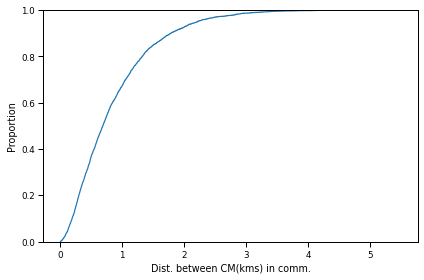

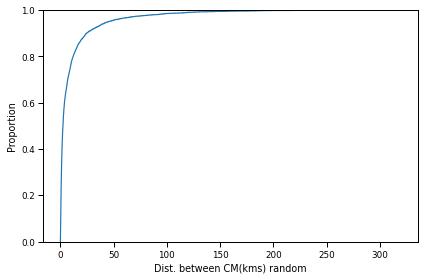

In [98]:
dcom=[]
dcom_rand=[]
def comdist(p1, p2):
	return np.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)/1000

for i in range(len(col_ind)):
	dcom.append(comdist(rcm_array[trajs_dakar[row_ind[i]]], rcm_array[trajs_dakar[col_ind[i]]]))
	
	dcom_rand.append(comdist(rcm_array[trajs_senegal_random[row_ind_random[i]]], rcm_array[trajs_senegal_random[col_ind_random[i]]]))

plot_dist(dcom, "Dist. between CM(kms) in comm.", "dcom")
plot_dist(dcom_rand, "Dist. between CM(kms) random", "dcom_rand")

In [99]:
print("Making full K-merge matrix")

rows, cols = knn_m[1].nonzero()
chosen_k=100

num_cores=32
# indexes=[]

# for i in range(num_cores):
# 	il = int(num_trajs/num_cores)
# 	indexes.append([j for j in range(i*il, i*il+il)])

Making full K-merge matrix


In [100]:
print(rows, len(rows), cols, len(cols))

[   0    0    0 ... 4999 4999 4999] 100000 [   0 4561  902 ... 4574 4737 2339] 100000


In [101]:
import math

# K=100
# arr_kmerge_cost_knn = np.zeros( (num_trajs_dakar, K) ) #(num_trajs_dakar, K)
# nn_dakar=defaultdict(list)

# for j, traj in enumerate(trajs_dakar):
# 	global K, num_trajs_dakar
# # 	print(key)
# 	index0=traj*K
# # 	this_neighbours=[]
# 	for i in range(K):
# # 		print(traj, i, kmerge_cost[(traj, cols[index0+i])]) #dk_trajs_dict[cols[index0+i]]
# 		if len(kmerge_cost[(traj, cols[index0+i])]):
# 			arr_kmerge_cost_knn[dk_trajs_dict[traj]][i]=kmerge_cost[(traj, cols[index0+i])][0]
# 		else:
# 			arr_kmerge_cost_knn[dk_trajs_dict[traj]][i]=np.mean(arr_kmerge_cost_knn[dk_trajs_dict[traj]])
# # 			print("Non-existing edge!")
# 		nn_dakar[dk_trajs_dict[traj]].append(cols[index0+i])
# # 	for i in range(K, num_trajs_dakar):
# # 		arr_kmerge_cost_knn[dk_trajs_dict[traj]][i]=math.inf
# # 		nn_dakar[dk_trajs_dict[traj]].append(math.inf)

# print(arr_kmerge_cost_knn)

In [102]:
# arr_kmerge_cost_knn_random = np.zeros( (num_trajs_dakar, K) )
# nn_random=defaultdict(list)

# for j, traj in enumerate(trajs_senegal_random):
# # 	print(key)
# 	index0=traj*K
# # 	this_neighbours=[]
# 	for i in range(K):
# # 		print(traj, index0+i, cols[index0+i]) #dk_trajs_dict[cols[index0+i]]
# 		if len(kmerge_cost[(traj, cols[index0+i])]):
# 			arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]][i]=kmerge_cost[(traj, cols[index0+i])][0]
# 		else:
# 			arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]][i]=np.mean(arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]])
# # 			print("Non-existing edge!")
# 		nn_random[dk_trajs_dict_random[traj]].append(cols[index0+i])

# print(arr_kmerge_cost_knn_random)

In [103]:
count = 0
flag=0

for key in kmerge_cost.keys():
	if key[0]==79:
# 		print(key)
		count = count + 1
		flag=1
	if flag==1 and key[0]!=79:
		break

# print(count)

In [104]:
# row_ind_knn, col_ind_knn = linear_sum_assignment(arr_kmerge_cost_knn) #, maximize=True
# col_ind
# array([1, 0, 2])
# cost[row_ind, col_ind].sum()

In [105]:
# row_ind_knn_random, col_ind_knn_random = linear_sum_assignment(arr_kmerge_cost_knn_random) #, maximize=True

In [106]:
# print(col_ind_knn, row_ind_knn)
# arr_kmerge_cost_knn[row_ind_knn, col_ind_knn].sum()

In [107]:
# print(col_ind_knn_random, row_ind_knn_random)
# arr_kmerge_cost_knn_random[row_ind_knn_random, col_ind_knn_random].sum()

In [108]:
# print(arr_kmerge_cost_knn.shape, arr_kmerge_cost_knn_random.shape)

# Test if the hungarian lies withing the Nearest neighbours

In [109]:
## We need to check the overlap of the KNN with the actual optimality. Might be expressed as a percentage!

In [110]:
## This might suffice the problem of rectangular matrix in the case of the nearest neighbours.

In [111]:
def knn_inclusiveness(nn_dakar):
	global row_ind, dk_trajs_reverse, col_ind
	
	inclusiveness=0
	# print(dk_trajs_reverse)
	# need a reverse dictionary

	for i, tr in enumerate(row_ind):
		if col_ind[i] in nn_dakar[i]:
	# 		print(nn_dakar[i])
			inclusiveness = inclusiveness + 1

	print("The inclusiveness is: ", (inclusiveness/len(row_ind))*100, " percent with: ", inclusiveness, " trajs. inside the nearest neighbours.")
	return (inclusiveness/len(row_ind))*100

In [112]:
def knn_inclusivenss_random(nn_random):
	global row_ind_knn, dk_trajs_reverse_random, col_ind_knn
	
	inclusiveness=0
	# print(dk_trajs_reverse)
	# need a reverse dictionary

	for i, tr in enumerate(row_ind_random):
		if col_ind_random[i] in nn_random[i]:
	# 		print(nn_dakar[i])
			inclusiveness = inclusiveness + 1

	print("The inclusiveness(random trajs.) is: ", (inclusiveness/len(row_ind_random))*100, " with: ", inclusiveness, " trajs. inside the nearest neighbours.")
	return (inclusiveness/len(row_ind_random))*100

In [113]:
## Check the difference in the cost between the min. of node's nearest neighbours and the optimal assignment.

In [114]:
## What if we increase the size of the considered num. of nearest neighbours?

In [115]:
# knn_cost=0
# for i in range(len(arr_kmerge_cost_knn)):
# 	knn_cost = knn_cost + min(arr_kmerge_cost[i])

# print(knn_cost, knn_cost-arr_kmerge_cost[row_ind, col_ind].sum())

In [116]:
# knn_cost=0
# for i in range(len(arr_kmerge_cost_knn_random)):
# 	knn_cost = knn_cost + min(arr_kmerge_cost_random[i])

# print(knn_cost, knn_cost-arr_kmerge_cost_random[row_ind_random, col_ind_random].sum())

## Compare deta Cost vs Inclusiveness

In [117]:
# def get_knn_cost(K, idex):
# 	global num_trajs_dakar, knn_m
	
# 	rows, cols = knn_m[idex].nonzero()
# # 	print(max(cols))
	
# 	arr_kmerge_cost_knn = np.full( (num_trajs_dakar, num_trajs_dakar), math.inf ) #(num_trajs_dakar, K)
# 	nn_dakar=defaultdict(list)

# 	for j, traj in enumerate(trajs_dakar):
# 	# 	print(key)
# 		index0=traj*K
# 		for i in range(K):
# 			print(traj) #dk_trajs_dict[cols[index0+i]]
# 			if len(kmerge_cost_dakar[(traj, cols[index0+i])]):
# 				arr_kmerge_cost_knn[dk_trajs_dict[traj]][dk_trajs_dict[cols[index0+i]]]=kmerge_cost_dakar[(traj, cols[index0+i])][0]
# 			else:
# 				arr_kmerge_cost_knn[dk_trajs_dict[traj]][dk_trajs_dict[cols[index0+i]]]=math.inf #np.mean(arr_kmerge_cost_knn[dk_trajs_dict[traj]])
# 	# 			print("Non-existing edge!")
# 			nn_dakar[dk_trajs_dict[traj]].append(cols[index0+i])

# # 	print(arr_kmerge_cost_knn)
# 	return arr_kmerge_cost_knn, nn_dakar

In [118]:
def get_knn_cost(K, idex):
	global num_trajs_dakar, knn_m
	
	rows, cols = knn_m[idex].nonzero()
# 	print(max(cols))
	
	arr_kmerge_cost_knn = np.full( (num_trajs_dakar, num_trajs_dakar), math.inf ) #(num_trajs_dakar, K)
	nn_dakar=defaultdict(list)

	for j in range(num_trajs_dakar):
	# 	print(key)
		index0=j*K
		traj=j
		for i in range(K):
# 			print((traj, cols[index0+i])) #dk_trajs_dict[cols[index0+i]]
# 			if len(kmerge_cost_dakar[(traj, cols[index0+i])]):
			if traj==cols[index0+i]:
				arr_kmerge_cost_knn[traj][cols[index0+i]]=math.inf
			else:
				arr_kmerge_cost_knn[traj][cols[index0+i]]=kmerge_cost_dakar[(traj, cols[index0+i])][0]
# 			else:
# # 				arr_kmerge_cost_knn[dk_trajs_dict[traj]][dk_trajs_dict[cols[index0+i]]]=math.inf #np.mean(arr_kmerge_cost_knn[dk_trajs_dict[traj]])
# 				print("Non-existing edge!")
			nn_dakar[traj].append(cols[index0+i])

# 	print(arr_kmerge_cost_knn)
	return arr_kmerge_cost_knn, nn_dakar

In [119]:
# print(trajs_dakar)

In [120]:
# def get_knn_cost_random(K, idex):
# 	global num_trajs_dakar, knn_m
	
# 	rows, cols = knn_m_random[idex].nonzero()
	
# 	arr_kmerge_cost_knn_random = np.full( (num_trajs_dakar, num_trajs_dakar), math.inf )
# 	nn_random=defaultdict(list)

# 	for j, traj in enumerate(trajs_senegal_random):
# 	# 	print(key)
# 		index0=traj*K
# 	# 	this_neighbours=[]
# 		for i in range(K):
# 	# 		print(traj, index0+i, cols[index0+i]) #dk_trajs_dict[cols[index0+i]]
# 			if len(kmerge_cost[(traj, cols[index0+i])]):
# 				arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]][dk_trajs_dict_random[cols[index0+i]]]=kmerge_cost[(traj, cols[index0+i])][0]
# 			else:
# 				arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]][dk_trajs_dict_random[cols[index0+i]]]=math.inf #np.mean(arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]])
# 	# 			print("Non-existing edge!")
# 			nn_random[dk_trajs_dict_random[traj]].append(cols[index0+i])

# # 	print(arr_kmerge_cost_knn_random)
# 	return arr_kmerge_cost_knn_random, nn_random

In [121]:
def get_knn_cost_random(K, idex):
	global num_trajs_dakar, knn_m
	
	rows, cols = knn_m_random[idex].nonzero()
	
	arr_kmerge_cost_knn_random = np.full( (num_trajs_dakar, num_trajs_dakar), math.inf )
	nn_random=defaultdict(list)

	for j in range(num_trajs_dakar):
	# 	print(key)
		traj=j
		index0=j*K
		for i in range(K):
	# 		print(traj, index0+i, cols[index0+i]) #dk_trajs_dict[cols[index0+i]]
# 			if len(kmerge_cost_senegal_random[(traj, cols[index0+i])]):
			if traj==cols[index0+i]:
				arr_kmerge_cost_knn_random[traj][cols[index0+i]]=math.inf
			else:
				arr_kmerge_cost_knn_random[traj][cols[index0+i]]=kmerge_cost_senegal_random[(traj, cols[index0+i])][0]
# 			else:
# 				arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]][dk_trajs_dict_random[cols[index0+i]]]=math.inf #np.mean(arr_kmerge_cost_knn_random[dk_trajs_dict_random[traj]])
	# 			print("Non-existing edge!")
			nn_random[traj].append(cols[index0+i])

# 	print(arr_kmerge_cost_knn_random)
	return arr_kmerge_cost_knn_random, nn_random

In [122]:
def lassignment(cost_m, K, strategy):
	global num_trajs_dakar
	
	count=0
	cost=0
	ca=cost_m
	
	if strategy == 1:
		while(count<num_trajs_dakar):
			ri, ci = linear_sum_assignment(ca) #, maximize=True
			this_cost=ca[ri, ci].sum()
	# 		print(this_cost)

			ca = np.delete(ca, ri, axis=0)

			count=count+K
			cost=cost+this_cost
	
	elif strategy == 2:
		num_it = int(num_trajs_dakar/K)
		for i in range(num_it):
			ri, ci = linear_sum_assignment(ca[i*K : (i+1)*K]) #, maximize=True
			this_cost=ca[i*K : (i+1)*K][ri, ci].sum()
	# 		print(this_cost)

			cost=cost+this_cost
	
	elif strategy == 3:
		num_it = int(num_trajs_dakar/K)
		flags = [1 for i in range(num_trajs_dakar)]
		idx_random = []
		
		for i in range(num_it):
			this_rand=set()
			while len(this_rand)<K:
				idx = random.randint(0, num_trajs_dakar-1)
				if flags[idx]==1:
					this_rand.add(idx)
					flags[idx]=0
			idx_random.append(list(this_rand))
		
		for i in range(num_it):
			ri, ci = linear_sum_assignment(ca[idx_random[i]]) #, maximize=True
			this_cost=ca[idx_random[i]][ri, ci].sum()
			
			cost=cost+this_cost
	
	elif strategy == 4:
		ri, ci = linear_sum_assignment(ca) #, maximize=True
		cost=ca[ri, ci].sum()
	return cost, (ri, ci)

In [123]:
strategy=4

cost_knn=[]
cost_knn_random=[]
inclusiveness_knn=[]
inclusiveness_knn_random=[]
idss_array=[]
idss_array_rand=[]

for idex, K_SIZE in enumerate(ck_vals):
	aknn, nn_dakar=get_knn_cost(K_SIZE, idex)
	aknn_random, nn_random=get_knn_cost_random(K_SIZE, idex)

	min_vals1 = [math.inf for i in range(num_trajs_dakar)]
	min_vals2 = [math.inf for i in range(num_trajs_dakar)]
	
	for row in aknn:
		for i, val in enumerate(row):
			if val < min_vals1[i]:
				min_vals1[i]=val
	
	for row in aknn_random:
		for i, val in enumerate(row):
			if val < min_vals2[i]:
				min_vals2[i]=val
	
	count1, count2=0,0
	inf_cols1, inf_cols2=[],[]
	for i, val in enumerate(min_vals1):
		if val == math.inf:
			count1=count1+1
			inf_cols1.append(i)
	for i, val in enumerate(min_vals2):
		if val == math.inf:
			count2=count2+1
			inf_cols2.append(i)

	print(count1, " and ", count2, " number of cols. have just inf. values in community and random respectively!")
	if count1>0:
		aknn = np.delete(aknn, inf_cols1, axis=0)
		aknn = np.delete(aknn, inf_cols1, axis=1)
	if count2>0:
		aknn_random = np.delete(aknn_random, inf_cols2, axis=0)
		aknn_random = np.delete(aknn_random, inf_cols2, axis=1)
	
# 	print(aknn.shape, aknn_random.shape)
	thiss_cost1, idss1 = lassignment(aknn, K_SIZE, strategy)
	cost_knn.append(thiss_cost1-gt_knn)
	idss_array_rand.append(idss1)
	try:
		thiss_cost, idss = lassignment(aknn_random, K_SIZE, strategy)
		idss_array.append(idss)
		cost_knn_random.append(thiss_cost-gt_knn_random)
	except:
		cost_knn_random.append(math.inf)
	
	inclusiveness_knn.append(knn_inclusiveness(nn_dakar))
	inclusiveness_knn_random.append(knn_inclusivenss_random(nn_random))

5  and  5  number of cols. have just inf. values in community and random respectively!
The inclusiveness is:  2.12  percent with:  106  trajs. inside the nearest neighbours.
The inclusiveness(random trajs.) is:  35.6  with:  1780  trajs. inside the nearest neighbours.
1  and  1  number of cols. have just inf. values in community and random respectively!
The inclusiveness is:  4.16  percent with:  208  trajs. inside the nearest neighbours.
The inclusiveness(random trajs.) is:  46.32  with:  2316  trajs. inside the nearest neighbours.
1  and  1  number of cols. have just inf. values in community and random respectively!
The inclusiveness is:  6.18  percent with:  309  trajs. inside the nearest neighbours.
The inclusiveness(random trajs.) is:  52.88  with:  2644  trajs. inside the nearest neighbours.
1  and  1  number of cols. have just inf. values in community and random respectively!
The inclusiveness is:  8.04  percent with:  402  trajs. inside the nearest neighbours.
The inclusiveness

In [124]:
# for j in range(len(idss_array)):
# 	dcom=[]
# 	dcom_rand=[]
# 	for i in range(len(idss_array[j][0])):
# 		dcom.append(comdist(rcm_array[trajs_dakar[idss_array[j][0][i]]], rcm_array[trajs_dakar[idss_array[j][1][i]]]))

# 		dcom_rand.append(comdist(rcm_array[trajs_senegal_random[idss_array_rand[j][0][i]]], rcm_array[trajs_senegal_random[idss_array_rand[j][1][i]]]))

# 	plot_dist(dcom, "Dist. between CM(kms) in comm.", "dcom"+str(j))
# 	plot_dist(dcom_rand, "Dist. between CM(kms) random", "dcom_rand"+str(j))

/tmp/ipykernel_2370944/450242830.py:32: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b-" (-> linestyle='-'). The keyword argument will take precedence.
  ax2.plot(ck_vals, inclusiveness_knn_random, 'b-', label="random", linestyle='--', linewidth=2, marker='o')


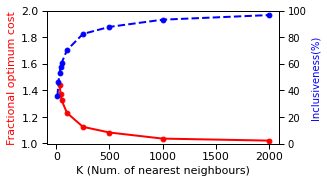

In [148]:
# ck_vals = ck_vals[:-2]
# cost_knn = cost_knn[:-2]
# cost_knn_random = cost_knn_random[:-2]

fig, ax = plt.subplots(1, 1) 

# Adjust font sizes for specific plot elements
plt.rc('axes', labelsize=10)    # Font size for x and y labels
plt.rc('xtick', labelsize=10)   # Font size for x-tick labels
plt.rc('ytick', labelsize=10)   # Font size for y-tick labels
plt.rc('legend', fontsize=10)   # Font size for legend
plt.rc('figure', titlesize=10)  # Font size for figure title (if used)

# ax[0].plot(ck_vals, [(cst+gt_knn) for cst in cost_knn], 'g-', label="community(cost)")
# ax.plot(ck_vals, [(cst+gt_knn_random) for cst in cost_knn_random], 'r-', label="random(cost)")
# ax[2].plot(ck_vals, [(cst+gt_knn)/gt_knn for cst in cost_knn], 'g-', label="community(cost)")

ax.plot(ck_vals, [(cst+gt_knn_random)/gt_knn_random for cst in cost_knn_random], 'r-', linewidth=2, marker='o', label="random(cost)")

ax2 = ax.twinx()

# ax2.plot(ck_vals, [(cst+gt_knn_random)/gt_knn_random for cst in cost_knn_random], 'r-', label="random(cost)")
# ax[4].plot(ck_vals, [(cst+gt_knn_random)/gt_knn for cst in cost_knn_random], 'r-', label="random(cost)")


# ax2 = ax[0].twinx()
# ax2.plot(ck_vals, inclusiveness_knn, 'b-', label="community")
# ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'
# ax2.set_ylim([0, 100])

# ax2 = ax.twinx()
ax2.plot(ck_vals, inclusiveness_knn_random, 'b-', label="random", linestyle='--', linewidth=2, marker='o')
ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'
ax2.set_ylim([0, 100])

# ax2 = ax[2].twinx()
# ax2.plot(ck_vals, inclusiveness_knn, 'b-', label="community")
# ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'
# ax2.set_ylim([0, 100])

# ax2 = ax[1].twinx()
# ax2.plot(ck_vals, inclusiveness_knn_random, 'y-', label="random")
# ax2.set_ylim([0, 100])

ax.set_xlabel('K (Num. of nearest neighbours)')
# ax[0].set_ylabel('Total merge cost', color='g')#, color='g'
# ax[0].set_ylabel('Total merge cost', color='r')#, color='g'
# ax[2].set_ylabel('Frac. opt. cost', color='g')#, color='g'
ax.set_ylabel('Fractional optimum cost', color='r')#, color='g'
# ax[4].set_ylabel('Frac. opt. cost', color='r')#, color='g'
ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'

# ax2 = ax[4].twinx()
# ax2.plot(ck_vals, inclusiveness_knn_random, 'y-', label="random")
# ax2.set_ylabel('Inclusiveness(%)', color='y')#, color='b'
# ax2.set_ylim([0, 100])

ax.set_ylim([1, 2])
# ax[3].set_ylim([1, 2])
# ax[4].set_ylim([1, 15])

# ax[0].set_ylim([1, 2])
# ax[1].set_ylim([1, 2])

# plt.xlabel("Num. of nearest neighbours")
# plt.ylabel("Time to construct KNN (s)")

# # # ax[0].set_title("Community trajs.")
# ax[0].set_title("Random trajs.")
# # ax[2].set_title("Community trajs.")
# ax[1].set_title("Random trajs.")
# # ax[4].set_title("Random trajs.(wrt. community optimal cost)")

# plt.rcParams["font.size"] = "55" 

plt.savefig("delta_cost_inclusiveness_final" + str(strategy) + ".pdf")

In [126]:
print([(cst+gt_knn)/gt_knn for cst in cost_knn], [(cst+gt_knn_random)/gt_knn_random for cst in cost_knn_random])

[1.7745495193596008, 1.5631186542165447, 1.4719571860474738, 1.4187750114848443, 1.382076215447333, 1.2846171142793845, 1.1767167470233983, 1.110836748263808, 1.0596843640851479, 1.0246322399517593] [inf, inf, 1.4370223618536442, 1.372983867844565, 1.324027576504021, 1.2301118361794845, 1.1254242436654436, 1.0827496659560853, 1.0368916985744412, 1.021800979148614]


## Find a law for the size of K

In [127]:
frac_cost_size_shenzen=defaultdict(list)
frac_cost_density_shenzen=defaultdict(list)

gt_cost_size_shenzen=defaultdict(list)
gt_cost_density_shenzen=defaultdict(list)

total_merge_cost_size_shenzen=defaultdict(list)
total_merge_cost_density_shenzen=defaultdict(list)

knn_m_size_shenzen=defaultdict(list)
knn_m_density_shenzen=defaultdict(list)

In [128]:
files_density_shenzen = ["com_trajectories_shenzen_density12.0.pickle", "com_trajectories_shenzen_density18.0.pickle", "com_trajectories_shenzen_density23.0.pickle", "com_trajectories_shenzen_density27.0.pickle"] 

files_size_shenzen = ["com_trajectories_shenzen_size18.pickle", "com_trajectories_shenzen_size19.pickle", "com_trajectories_shenzen_size5.pickle", "com_trajectories_shenzen_size9.pickle"]

In [129]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5, 

for file in files_size_shenzen:
	for K_SIZE in tqdm(ck_vals):
		try:
			with open('size_knn_shenzen/knn_matrix_shenzen_' + file.split(".")[0].split("_")[3] + "_" + str(K_SIZE) +  '.pickle', 'rb') as handle:
				knn_m_size_shenzen[file.split(".")[0].split("_")[3]].append(pickle.load(handle))
		except:
			print("The KNN size does not exist!")

for file in files_density_shenzen:
	for K_SIZE in tqdm(ck_vals):
		try:
			with open('density_knn_shenzen/knn_matrix_shenzen_' + file.split(".")[0].split("_")[3] + "_" + str(K_SIZE) +  '.pickle', 'rb') as handle:
				knn_m_density_shenzen[file.split(".")[0].split("_")[3]].append(pickle.load(handle))
		except:
			print("The KNN size does not exist!")

100%|██████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 63.82it/s]


The KNN size does not exist!


100%|██████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 36.46it/s]


In [130]:
print(knn_m_density_shenzen.keys(), knn_m_size_shenzen.keys())

dict_keys(['density12', 'density18', 'density23', 'density27']) dict_keys(['size18', 'size19', 'size5', 'size9'])


In [131]:
trajs_size_shenzen=defaultdict(list)
trajs_density_shenzen=defaultdict(list)

In [132]:
def get_knn_cost_specific(K, knn_m, num_trajs, this_cost):
	rows, cols = knn_m.nonzero()
# 	print(len(rows), len(cols))
	
	arr_kmerge_cost_knn = np.full( (num_trajs, num_trajs), math.inf ) #(num_trajs_dakar, K)
	nn_this=defaultdict(list)

	for j in range(num_trajs):
	# 	print(key)
		index0=j*K
		traj=j
		for i in range(K):
# 			print((traj, cols[index0+i])) #dk_trajs_dict[cols[index0+i]]
# 			if len(kmerge_cost_dakar[(traj, cols[index0+i])]):
			if traj==cols[index0+i]:
				arr_kmerge_cost_knn[traj][cols[index0+i]]=math.inf
			else:
				arr_kmerge_cost_knn[traj][cols[index0+i]]=this_cost[(traj, cols[index0+i])][0]
# 			else:
# # 				arr_kmerge_cost_knn[dk_trajs_dict[traj]][dk_trajs_dict[cols[index0+i]]]=math.inf #np.mean(arr_kmerge_cost_knn[dk_trajs_dict[traj]])
# 				print("Non-existing edge!")
			nn_this[traj].append(cols[index0+i])

# 	print(arr_kmerge_cost_knn)
	return arr_kmerge_cost_knn, nn_this

In [133]:
import math

gt_indices_size_shenzen = defaultdict(tuple)
gt_indices_density_shenzen = defaultdict(tuple)

for file in tqdm(files_size_shenzen):
	case=file.split(".")[0].split("_")[3]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_shenzen_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	arr_kmerge_cost = np.zeros( (num_trajs, num_trajs) )

	for key in this_cost.keys():
		if key[0]==key[1]:
			arr_kmerge_cost[key[0]][key[1]]=math.inf
		else:
			arr_kmerge_cost[key[0]][key[1]]=this_cost[key][0]
	
	row_ind, col_ind = linear_sum_assignment(arr_kmerge_cost)
	gt_indices_size_shenzen[case]=(row_ind, col_ind)
	gt_cost_size_shenzen[case]=arr_kmerge_cost[row_ind, col_ind].sum()

for file in tqdm(files_density_shenzen):
	case=file.split(".")[0].split("_")[3]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_shenzen_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	arr_kmerge_cost = np.zeros( (num_trajs, num_trajs) )

	for key in this_cost.keys():
		if key[0]==key[1]:
			arr_kmerge_cost[key[0]][key[1]]=math.inf
		else:
			arr_kmerge_cost[key[0]][key[1]]=this_cost[key][0]
	
	row_ind, col_ind = linear_sum_assignment(arr_kmerge_cost)
	gt_indices_density_shenzen[case]=(row_ind, col_ind)
	gt_cost_density_shenzen[case]=arr_kmerge_cost[row_ind, col_ind].sum()

  0%|                                                                                | 0/4 [00:17<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
def lassignment_specific(cost_m, K):
	ca=cost_m
	
	ri, ci = linear_sum_assignment(ca) #, maximize=True
	cost=ca[ri, ci].sum()
	return cost, (ri, ci)

In [ ]:
def knn_inclusiveness_specific(nn_this, row_ind, col_ind):
	inclusiveness=0

	for i, tr in enumerate(row_ind):
		if col_ind[i] in nn_this[i]:
	# 		print(nn_dakar[i])
			inclusiveness = inclusiveness + 1

	print("The inclusiveness is: ", (inclusiveness/len(row_ind))*100, " percent with: ", inclusiveness, " trajs. inside the nearest neighbours.")
	return (inclusiveness/len(row_ind))*100

In [ ]:
inclusiveness_size_shenzen=defaultdict(list)
inclusiveness_density_shenzen=defaultdict(list)

In [ ]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5,

# for file in tqdm(files_size_shenzen):
# 	case=file.split(".")[0].split("_")[3]
# 	with open(file, 'rb') as handle:
# 		trajs_this = pickle.load(handle)
	
# 	with open('kmerge_costs_shenzen_' + case + '.pickle', 'rb') as handle:
# 		this_cost = pickle.load(handle)
	
# 	num_trajs = len(trajs_this)
	
# 	for idex, K_SIZE in enumerate(ck_vals):
# 		if num_trajs > K_SIZE:
# 			aknn, nn_this=get_knn_cost_specific(K_SIZE, knn_m_size_shenzen[case][idex], num_trajs, this_cost)

# 			min_vals1 = [math.inf for i in range(num_trajs)]

# 			for row in aknn:
# 				for i, val in enumerate(row):
# 					if val < min_vals1[i]:
# 						min_vals1[i]=val

# 			count1 = 0
# 			inf_cols1 = []
# 			for i, val in enumerate(min_vals1):
# 				if val == math.inf:
# 					count1=count1+1
# 					inf_cols1.append(i)

# 			print(count1, " number of cols. have just inf. values in community!")
# 			if count1>0:
# 				aknn = np.delete(aknn, inf_cols1, axis=0)
# 				aknn = np.delete(aknn, inf_cols1, axis=1)

# 		# 	print(aknn.shape, aknn_random.shape)
# 			thiss_cost1, idss1 = lassignment_specific(aknn, K_SIZE)
# 			total_merge_cost_size_shenzen[case].append(thiss_cost1-gt_cost_size_shenzen[case])

# 			inclusiveness_size_shenzen[case].append(knn_inclusiveness_specific(nn_this, gt_indices_size_shenzen[case][0], gt_indices_size_shenzen[case][1]))

for file in tqdm(files_density_shenzen):
	case=file.split(".")[0].split("_")[3]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_shenzen_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	
	for idex, K_SIZE in enumerate(ck_vals):
		if num_trajs > K_SIZE:
			aknn, nn_this=get_knn_cost_specific(K_SIZE, knn_m_density_shenzen[case][idex], num_trajs, this_cost)

			min_vals1 = [math.inf for i in range(num_trajs)]

			for row in aknn:
				for i, val in enumerate(row):
					if val < min_vals1[i]:
						min_vals1[i]=val

			count1 = 0
			inf_cols1 = []
			for i, val in enumerate(min_vals1):
				if val == math.inf:
					count1=count1+1
					inf_cols1.append(i)

			print(count1, " number of cols. have just inf. values in community!")
			if count1>0:
				aknn = np.delete(aknn, inf_cols1, axis=0)
				aknn = np.delete(aknn, inf_cols1, axis=1)

		# 	print(aknn.shape, aknn_random.shape)
			thiss_cost1, idss1 = lassignment_specific(aknn, K_SIZE)
			total_merge_cost_density_shenzen[case].append(thiss_cost1-gt_cost_density_shenzen[case])

			inclusiveness_density_shenzen[case].append(knn_inclusiveness_specific(nn_this, gt_indices_density_shenzen[case][0], gt_indices_density_shenzen[case][1]))

In [ ]:
print(total_merge_cost_density_shenzen, total_merge_cost_size_shenzen)

print(gt_cost_size_shenzen, gt_cost_density_shenzen)

# print(gt_indices_size_shenzen, gt_indices_density_shenzen)

In [ ]:
# ck_vals = ck_vals[:-2]
# cost_knn = cost_knn[:-2]
# cost_knn_random = cost_knn_random[:-2]

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

j=0
ax2 = ax[0].twinx()
for idd in com_id_size_shenzen:
	val1 = []
	val2 = []
	count=0
	for i in range(len(ck_vals)):
		try:
			val1.append( (total_merge_cost_size_shenzen['size'+str(int(idd))][i] + gt_cost_size_shenzen['size'+str(int(idd))])/gt_cost_size_shenzen['size'+str(int(idd))] )
			val2.append( inclusiveness_size_shenzen['size'+str(int(idd))][i] )
			count=i
		except:
			pass
	ax[0].plot(ck_vals[ : count+1], val1, label=com_size[j])
	ax2.plot(ck_vals[ : count+1], val2, label=com_size[j])
	j=j+1

j=0
ax3 = ax[1].twinx()
for idd in com_id_density_shenzen:
	val1 = []
	val2 = []
	count=0
	for i in range(len(ck_vals)):
		try:
			val1.append( (total_merge_cost_density_shenzen['density'+str(int(idd))][i] + gt_cost_density_shenzen['density'+str(int(idd))])/gt_cost_density_shenzen['density'+str(int(idd))] )
			val2.append( inclusiveness_density_shenzen['density'+str(int(idd))][i] )
			count=i
		except:
			pass
	if count!=0:
		ax[1].plot(ck_vals[ : count+1], val1, label=com_density_shenzen[j])
		ax3.plot(ck_vals[ : count+1], val2, label=com_density_shenzen[j])
		
		j=j+1

ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'
ax3.set_ylabel('Inclusiveness(%)', color='y')#, color='b'

ax2.set_ylim([0, 100])
ax3.set_ylim([0, 100])

ax[1].set_xlabel('K (Num. of nearest neighbours)')
ax[0].set_ylabel('Frac. opt. cost', color='g')#, color='g'
ax[1].set_ylabel('Frac. opt. cost', color='r')#, color='g'

ax[0].set_ylim([1, 1.5])
ax[1].set_ylim([1, 1.5])

# plt.xlabel("Num. of nearest neighbours")
# plt.ylabel("Time to construct KNN (s)")

ax[0].legend(title="Community size", bbox_to_anchor=(1.30, 1.05),
          ncol=1, fancybox=True, shadow=True)
ax[1].legend(title="Community's density", loc="best", bbox_to_anchor=(1.30, 1.05),
          ncol=1, fancybox=True, shadow=True)

ax[0].set_title("Size variation")
ax[1].set_title("Density variation")

plt.savefig("delta_cost_shenzen.pdf")

In [ ]:
ck_vals=[500, 1000, 2000]

val1 = defaultdict(list)
for idd in com_id_size_shenzen:
	for i in range(len(ck_vals)):
		v = (total_merge_cost_size_shenzen['size'+str(int(idd))][i-3] + gt_cost_size_shenzen['size'+str(int(idd))])/gt_cost_size_shenzen['size'+str(int(idd))]
		val1[ck_vals[i]].append( v )
df = pd.DataFrame.from_dict(val1)
df["Community size"]=com_size
df = df.melt(id_vars="Community size")
df.columns=["Community size", "K (Num. of nearest neighbours)", "Frac. opt. cost"]

g = sns.catplot( data=df, kind="bar", x="K (Num. of nearest neighbours)", y="Frac. opt. cost", hue="Community size", palette="dark", alpha=.6, height=6, legend_out=False)
plt.ylim([1.0, 1.1])
plt.savefig("size_kvars_shenzen.pdf")

val1 = defaultdict(list)
for idd in com_id_density_shenzen:
	for i in range(len(ck_vals)):
		v = (total_merge_cost_density_shenzen['density'+str(int(idd))][i-3] + gt_cost_density_shenzen['density'+str(int(idd))])/gt_cost_density_shenzen['density'+str(int(idd))]
		val1[ck_vals[i]].append( v )

df = pd.DataFrame.from_dict(val1)
df["Community's density"]=com_density_shenzen
df = df.melt(id_vars="Community's density")
df.columns=["Community's density", "K (Num. of nearest neighbours)", "Frac. opt. cost"]

g = sns.catplot( data=df, kind="bar", x="K (Num. of nearest neighbours)", y="Frac. opt. cost", hue="Community's density", palette="dark", alpha=.6, height=6, legend_out=False)
plt.ylim([1.0, 1.1])
plt.savefig("density_kvars_shenzen.pdf")

In [ ]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000]

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

j=0
val1=defaultdict(list)
for idd in com_id_size_shenzen:
	count=0
	for i in range(len(ck_vals)):
		try:
			val1[ck_vals[i]].append( (total_merge_cost_size_shenzen['size'+str(int(idd))][i] + gt_cost_size_shenzen['size'+str(int(idd))])/gt_cost_size_shenzen['size'+str(int(idd))] )
			count=i
		except:
			pass
	j=j+1
for key in val1.keys():
	ax[0].plot(com_size[len(com_size) - len(val1[key]): ], val1[key], label=key, marker="x")

j=0
val1=defaultdict(list)
for idd in com_id_density_shenzen:
	count=0
	for i in range(len(ck_vals)):
		try:
			val1[ck_vals[i]].append( (total_merge_cost_density_shenzen['density'+str(int(idd))][i] + gt_cost_density_shenzen['density'+str(int(idd))])/gt_cost_density_shenzen['density'+str(int(idd))] )
			count=i
		except:
			pass
	if count!=0:
		j=j+1
for key in val1.keys():
	ax[1].plot([math.log10(cm) for cm in com_density_shenzen], val1[key], label=key, marker="x")

ax[0].set_xlabel("Community size")#'K (Num. of nearest neighbours)'
ax[1].set_xlabel("Community's density (log10)")

ax[0].set_ylabel('Frac. opt. cost', color='g')#, color='g'
ax[1].set_ylabel('Frac. opt. cost', color='r')#, color='g'

# ax[0].set_ylim([1, 2.0])
# ax[1].set_ylim([1, 2.0])

# plt.xlabel("Num. of nearest neighbours")
# plt.ylabel("Time to construct KNN (s)")

ax[0].legend(title="K (Num. of nearest neighbours)")
ax[1].legend(title="K (Num. of nearest neighbours)")

ax[0].set_title("Size variation")
ax[1].set_title("Density variation")

plt.savefig("delta_cost_shenzen_size.pdf")

In [ ]:
frac_cost_size=defaultdict(list)
frac_cost_density=defaultdict(list)

gt_cost_size=defaultdict(list)
gt_cost_density=defaultdict(list)

total_merge_cost_size=defaultdict(list)
total_merge_cost_density=defaultdict(list)

knn_m_size=defaultdict(list)
knn_m_density=defaultdict(list)

In [ ]:
files_size = ["com_trajectories_size10.pickle", "com_trajectories_size37.pickle", "com_trajectories_size54.pickle", "com_trajectories_size67.pickle"]

files_density = ["com_trajectories_density39.0.pickle", "com_trajectories_density57.0.pickle", "com_trajectories_density65.0.pickle", "com_trajectories_density7.0.pickle"]

In [ ]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5, 

for file in files_size:
	for K_SIZE in tqdm(ck_vals):
		try:
			with open('size_knn/knn_matrix_' + file.split(".")[0].split("_")[2] + "_" + str(K_SIZE) +  '.pickle', 'rb') as handle:
				knn_m_size[file.split(".")[0].split("_")[2]].append(pickle.load(handle))
		except:
			print("The KNN size does not exist!")

for file in files_density:
	for K_SIZE in tqdm(ck_vals):
		try:
			with open('density_knn/knn_matrix_' + file.split(".")[0].split("_")[2] + "_" + str(K_SIZE) +  '.pickle', 'rb') as handle:
				knn_m_density[file.split(".")[0].split("_")[2]].append(pickle.load(handle))
		except:
			print("The KNN size does not exist!")

In [ ]:
print(knn_m_density.keys(), knn_m_size.keys())

In [ ]:
trajs_size=defaultdict(list)
trajs_density=defaultdict(list)

In [ ]:
import math

gt_indices_size = defaultdict(tuple)
gt_indices_density = defaultdict(tuple)

for file in tqdm(files_size):
	case=file.split(".")[0].split("_")[2]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	arr_kmerge_cost = np.zeros( (num_trajs, num_trajs) )

	for key in this_cost.keys():
		if key[0]==key[1]:
			arr_kmerge_cost[key[0]][key[1]]=math.inf
		else:
			arr_kmerge_cost[key[0]][key[1]]=this_cost[key][0]
	
	row_ind, col_ind = linear_sum_assignment(arr_kmerge_cost)
	gt_indices_size[case]=(row_ind, col_ind)
	gt_cost_size[case]=arr_kmerge_cost[row_ind, col_ind].sum()

for file in tqdm(files_density):
	case=file.split(".")[0].split("_")[2]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	arr_kmerge_cost = np.zeros( (num_trajs, num_trajs) )

	for key in this_cost.keys():
		if key[0]==key[1]:
			arr_kmerge_cost[key[0]][key[1]]=math.inf
		else:
			arr_kmerge_cost[key[0]][key[1]]=this_cost[key][0]
	
	row_ind, col_ind = linear_sum_assignment(arr_kmerge_cost)
	gt_indices_density[case]=(row_ind, col_ind)
	gt_cost_density[case]=arr_kmerge_cost[row_ind, col_ind].sum()

In [ ]:
inclusiveness_size=defaultdict(list)
inclusiveness_density=defaultdict(list)

In [ ]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5,

# for file in tqdm(files_size):
# 	case=file.split(".")[0].split("_")[2]
# 	with open(file, 'rb') as handle:
# 		trajs_this = pickle.load(handle)
	
# 	with open('kmerge_costs_' + case + '.pickle', 'rb') as handle:
# 		this_cost = pickle.load(handle)
	
# 	num_trajs = len(trajs_this)
# # 	print(num_trajs, case)
	
# 	for idex, K_SIZE in enumerate(ck_vals):
# 		if num_trajs > K_SIZE:
# 			try:
# 				aknn, nn_this=get_knn_cost_specific(K_SIZE, knn_m_size[case][idex], num_trajs, this_cost)

# 				min_vals1 = [math.inf for i in range(num_trajs)]

# 				for row in aknn:
# 					for i, val in enumerate(row):
# 						if val < min_vals1[i]:
# 							min_vals1[i]=val

# 				count1 = 0
# 				inf_cols1 = []
# 				for i, val in enumerate(min_vals1):
# 					if val == math.inf:
# 						count1=count1+1
# 						inf_cols1.append(i)

# 				print(count1, " number of cols. have just inf. values in community!")
# 				if count1>0:
# 					aknn = np.delete(aknn, inf_cols1, axis=0)
# 					aknn = np.delete(aknn, inf_cols1, axis=1)

# 			# 	print(aknn.shape, aknn_random.shape)
# 				thiss_cost1, idss1 = lassignment_specific(aknn, K_SIZE)
# 				total_merge_cost_size[case].append(thiss_cost1-gt_cost_size[case])

# 				inclusiveness_size[case].append(knn_inclusiveness_specific(nn_this, gt_indices_size[case][0], gt_indices_size[case][1]))
# 			except:
# 				print("cost matrix is infeasible")
				
# 				total_merge_cost_size[case].append(-1)
# 				inclusiveness_size[case].append(-1)

for file in tqdm(files_density):
	case=file.split(".")[0].split("_")[2]
	with open(file, 'rb') as handle:
		trajs_this = pickle.load(handle)
	
	with open('kmerge_costs_' + case + '.pickle', 'rb') as handle:
		this_cost = pickle.load(handle)
	
	num_trajs = len(trajs_this)
	print(case)
	
	for idex, K_SIZE in enumerate(ck_vals):
		if num_trajs > K_SIZE:
			try:
				aknn, nn_this=get_knn_cost_specific(K_SIZE, knn_m_density[case][idex], num_trajs, this_cost)

				min_vals1 = [math.inf for i in range(num_trajs)]

				for row in aknn:
					for i, val in enumerate(row):
						if val < min_vals1[i]:
							min_vals1[i]=val

				count1 = 0
				inf_cols1 = []
				for i, val in enumerate(min_vals1):
					if val == math.inf:
						count1=count1+1
						inf_cols1.append(i)

				print(count1, " number of cols. have just inf. values in community!")
				if count1>0:
					aknn = np.delete(aknn, inf_cols1, axis=0)
					aknn = np.delete(aknn, inf_cols1, axis=1)

			# 	print(aknn.shape, aknn_random.shape)
				thiss_cost1, idss1 = lassignment_specific(aknn, K_SIZE)
				total_merge_cost_density[case].append(thiss_cost1-gt_cost_density[case])

				inclusiveness_density[case].append(knn_inclusiveness_specific(nn_this, gt_indices_density[case][0], gt_indices_density[case][1]))
			except:
				print("cost matrix is infeasible")
				
				total_merge_cost_density[case].append(-1)
				inclusiveness_density[case].append(-1)

In [ ]:
print(total_merge_cost_density, total_merge_cost_size)

print(gt_cost_size, gt_cost_density)

# print(gt_indices_size, gt_indices_density)

In [ ]:
# ck_vals = ck_vals[:-2]
# cost_knn = cost_knn[:-2]
# cost_knn_random = cost_knn_random[:-2]

ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000] #2, 5,

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

j=0
ax2 = ax[0].twinx()
for idd in com_id_size:
	val1 = []
	val2 = []
	count=0
	for i in range(len(ck_vals)):
		try:
			v = (total_merge_cost_size['size'+str(int(idd))][i] + gt_cost_size['size'+str(int(idd))])/gt_cost_size['size'+str(int(idd))]
			if total_merge_cost_size['size'+str(int(idd))][i]!=-1:
				val1.append( v )
				count=count+1
				val2.append( inclusiveness_size['size'+str(int(idd))][i] )
		except:
			pass
	ax[0].plot(ck_vals[len(ck_vals) - count: ], val1, label=com_size[j])
	ax2.plot(ck_vals[len(ck_vals) - count: ], val2, label=com_size[j])
	j=j+1

j=0
ax3 = ax[1].twinx()
for idd in com_id_density:
	val1 = []
	val2 = []
	count=0
	for i in range(len(ck_vals)):
		try:
			v = (total_merge_cost_density['density'+str(int(idd))][i] + gt_cost_density['density'+str(int(idd))])/gt_cost_density['density'+str(int(idd))]
			if total_merge_cost_density['density'+str(int(idd))][i]!=-1:
				val1.append( v )
				count=count+1
				val2.append( inclusiveness_density['density'+str(int(idd))][i] )
		except:
			pass
	if count!=0:
		ax[1].plot(ck_vals[len(ck_vals) - count: ], val1, label=com_density[j])
		ax3.plot(ck_vals[len(ck_vals) - count: ], val2, label=com_density[j])
		j=j+1

ax2.set_ylabel('Inclusiveness(%)', color='b')#, color='b'
ax3.set_ylabel('Inclusiveness(%)', color='y')#, color='b'

ax2.set_ylim([0, 100])
ax3.set_ylim([0, 100])

ax[1].set_xlabel('K (Num. of nearest neighbours)')
ax[0].set_ylabel('Frac. opt. cost', color='g')#, color='g'
ax[1].set_ylabel('Frac. opt. cost', color='r')#, color='g'

ax[0].set_ylim([1, 1.8])
ax[1].set_ylim([1, 1.8])

ax[0].set_xlim([0, 2100])
ax[1].set_xlim([1, 2100])

# plt.xlabel("Num. of nearest neighbours")
# plt.ylabel("Time to construct KNN (s)")

ax[0].legend(title="Community size")
ax[1].legend(title="Community's density")

ax[0].set_title("Size variation")
ax[1].set_title("Density variation")

plt.savefig("delta_cost.pdf")

In [ ]:
ck_vals=[500, 1000, 2000]

val1 = defaultdict(list)
for idd in com_id_size:
	for i in range(len(ck_vals)):
		v = (total_merge_cost_size['size'+str(int(idd))][i-3] + gt_cost_size['size'+str(int(idd))])/gt_cost_size['size'+str(int(idd))]
		val1[ck_vals[i]].append( v )
df = pd.DataFrame.from_dict(val1)
df["Community size"]=com_size
df = df.melt(id_vars="Community size")
df.columns=["Community size", "K (Num. of nearest neighbours)", "Frac. opt. cost"]

g = sns.catplot( data=df, kind="bar", x="K (Num. of nearest neighbours)", y="Frac. opt. cost", hue="Community size", palette="dark", alpha=.6, height=6, legend_out=False)
plt.ylim([1.0, 1.3])
plt.savefig("size_kvars.pdf")

val1 = defaultdict(list)
for idd in com_id_density:
	for i in range(len(ck_vals)):
		v = (total_merge_cost_density['density'+str(int(idd))][i-3] + gt_cost_density['density'+str(int(idd))])/gt_cost_density['density'+str(int(idd))]
		val1[ck_vals[i]].append( v )

df = pd.DataFrame.from_dict(val1)
df["Community's density"]=com_density
df = df.melt(id_vars="Community's density")
df.columns=["Community's density", "K (Num. of nearest neighbours)", "Frac. opt. cost"]

g = sns.catplot( data=df, kind="bar", x="K (Num. of nearest neighbours)", y="Frac. opt. cost", hue="Community's density", palette="dark", alpha=.6, height=6, legend_out=False)
plt.ylim([1.0, 1.3])
plt.savefig("density_kvars.pdf")

In [ ]:
ck_vals=[10, 20, 30, 40, 50, 100, 250, 500, 1000, 2000]

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

j=0

val1=defaultdict(list)

for idd in com_id_size:
	count=0
	for i in range(len(ck_vals[-3:])):
		try:
			val1[ck_vals[i-3]].append( (total_merge_cost_size['size'+str(int(idd))][i-3] + gt_cost_size['size'+str(int(idd))])/gt_cost_size['size'+str(int(idd))] )
			count=i
		except:
			pass
	j=j+1
for key in val1.keys():
	ax[0].plot(com_size, val1[key], label=key, marker="x")

j=0
ax3 = ax[0].twinx()

val1=defaultdict(list)

for idd in com_id_density:
	count=0
	for i in range(len(ck_vals[-5:])):
		try:
			val1[ck_vals[i-5]].append( (total_merge_cost_density['density'+str(int(idd))][i-5] + gt_cost_density['density'+str(int(idd))])/gt_cost_density['density'+str(int(idd))] )
			count=i
		except:
			pass
	if count!=0:
		j=j+1
for key in val1.keys():
	ax[1].plot([math.log10(cm) for cm in com_density], val1[key], label=key, marker="x")

ax[0].set_xlabel("Community size")#'K (Num. of nearest neighbours)'
ax[1].set_xlabel("Community's density (log10)")

ax[0].set_ylabel('Frac. opt. cost', color='g')#, color='g'
ax[1].set_ylabel('Frac. opt. cost', color='r')#, color='g'

ax[0].set_ylim([1, 2.0])
ax[1].set_ylim([1, 2.0])

# plt.xlabel("Num. of nearest neighbours")
# plt.ylabel("Time to construct KNN (s)")

ax[0].legend(title="K (Num. of nearest neighbours)")
ax[1].legend(title="K (Num. of nearest neighbours)")

ax[0].set_title("Size variation")
ax[1].set_title("Density variation")

plt.savefig("delta_cost_size_senegal.pdf")